# 02 — Data Cleaning & Data Integrity

Notebook này chuyển dữ liệu từ `data/raw/` sang `data/processed/` sau khi kiểm tra và chuẩn hóa có kiểm soát.

**Nguyên tắc:**

1. `data/raw/` chỉ đọc, tuyệt đối không sửa hoặc ghi đè.
2. Không tự động xóa duplicate, dòng `unit_sales` âm, ngày lễ hoặc dòng có missing values.
3. Missing `onpromotion` và `oil.dcoilwtico` được giữ lại trong bước này; quyết định imputing cần có căn cứ và được ghi rõ ở bước feature engineering.
4. Dữ liệu lớn được đọc theo chunks. Nếu có PyArrow, đầu ra là Parquet; nếu không, notebook dùng CSV theo chunks.
5. Mọi phép biến đổi phải giữ nguyên số dòng. Nếu phát hiện lỗi cấu trúc hoặc khóa nghiệp vụ chưa thể xác minh, notebook sẽ dừng thay vì âm thầm sửa dữ liệu.

Thứ tự làm việc: kiểm tra schema → profile chất lượng raw → kiểm tra khóa và tham chiếu → xác nhận các điều kiện an toàn → chuẩn hóa/ghi dữ liệu → kiểm tra đầu ra và lưu báo cáo.


## 0. Configuration & runtime

Chạy notebook từ thư mục project hoặc một thư mục con bên trong project. Notebook tự tìm thư mục gốc có `data/raw/train.csv`.


In [1]:
from pathlib import Path
import json
import math
import os
import platform
import shutil
import time
from collections import defaultdict

import numpy as np
import pandas as pd
from IPython.display import display

try:
    import psutil
except ImportError:
    psutil = None

try:
    import pyarrow as pa
    import pyarrow.parquet as pq
    PARQUET_AVAILABLE = True
except ImportError:
    pa = None
    pq = None
    PARQUET_AVAILABLE = False

CHUNK_SIZE = 100_000
KEY_COLUMNS = ["date", "store_nbr", "item_nbr"]
OUTPUT_FORMAT = "parquet" if PARQUET_AVAILABLE else "csv"


def find_project_root(start: Path) -> Path:
    candidates = [start.resolve(), *start.resolve().parents]
    for candidate in candidates:
        if (candidate / "data" / "raw" / "train.csv").exists():
            return candidate
    raise FileNotFoundError(
        "Không tìm thấy data/raw/train.csv. Hãy mở notebook trong repository của project."
    )


PROJECT_ROOT = find_project_root(Path.cwd())
RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORT_TABLE_DIR = PROJECT_ROOT / "reports" / "table"
REPORT_DIR = PROJECT_ROOT / "reports"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
REPORT_TABLE_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project root : {PROJECT_ROOT}")
print(f"Raw directory: {RAW_DIR}")
print(f"Output format: {OUTPUT_FORMAT}")
print(f"Chunk size   : {CHUNK_SIZE:,} rows")
if psutil is not None:
    print(f"Available RAM: {psutil.virtual_memory().available / (1024**3):.2f} GiB")


Project root : /home/phat/Documents/Project/Machine Learning/Grocery-sales-forecast
Raw directory: /home/phat/Documents/Project/Machine Learning/Grocery-sales-forecast/data/raw
Output format: parquet
Chunk size   : 100,000 rows
Available RAM: 3.22 GiB


### Configuration notes

- `CHUNK_SIZE = 100_000` là giá trị khởi đầu an toàn; có thể giảm nếu máy thiếu RAM.
- Parquet được ưu tiên vì tiết kiệm dung lượng và giữ kiểu dữ liệu. Nếu không có PyArrow, notebook tự dùng CSV.
- Đầu ra là các file `*_cleaned.<format>` trong `data/processed/`. Các báo cáo chất lượng nằm trong `reports/` và `reports/table/`.


## 1. Schema validation

Bảng schema ở notebook `01` từng báo `id`, `city`, `cluster`, `state`, `type`, `family`, `class`, `perishable`, `dcoilwtico`, `description`, `locale`, `locale_name`, `transferred`, `transactions` là `extra_columns`. Đó không phải missing columns: các trường này chỉ chưa được khai báo trong tập cột kỳ vọng của cell kiểm tra schema.

Ở đây dùng schema chuẩn đầy đủ của bộ dữ liệu Favorita. `missing_required_columns` là những cột thực sự thiếu; `extra_columns` là cột ngoài schema đã khai báo và cần xem xét, không tự động xóa.


In [2]:
EXPECTED_COLUMNS = {
    "train.csv": {
        "id", "date", "store_nbr", "item_nbr", "unit_sales", "onpromotion"
    },
    "test.csv": {
        "id", "date", "store_nbr", "item_nbr", "onpromotion"
    },
    "stores.csv": {"store_nbr", "city", "state", "type", "cluster"},
    "items.csv": {"item_nbr", "family", "class", "perishable"},
    "oil.csv": {"date", "dcoilwtico"},
    "holidays_events.csv": {
        "date", "type", "locale", "locale_name", "description", "transferred"
    },
    "transactions.csv": {"date", "store_nbr", "transactions"},
}

missing_files = [name for name in EXPECTED_COLUMNS if not (RAW_DIR / name).exists()]
if missing_files:
    raise FileNotFoundError(f"Thiếu file trong data/raw/: {missing_files}")

schema_records = []
for filename, expected in EXPECTED_COLUMNS.items():
    actual = set(pd.read_csv(RAW_DIR / filename, nrows=0).columns)
    missing = sorted(expected - actual)
    extra = sorted(actual - expected)
    status = "MISSING_REQUIRED" if missing else ("REVIEW_EXTRA" if extra else "OK")
    schema_records.append({
        "file": filename,
        "status": status,
        "missing_required_columns": missing,
        "extra_columns": extra,
        "actual_column_count": len(actual),
        "expected_column_count": len(expected),
    })

schema_df = pd.DataFrame(schema_records)
display(schema_df)
schema_df.to_csv(REPORT_TABLE_DIR / "02_schema_validation.csv", index=False)

if (schema_df["status"] == "MISSING_REQUIRED").any():
    raise ValueError(
        "Có cột bắt buộc bị thiếu. Dừng trước cleaning; hãy xác minh đúng phiên bản dataset."
    )
if (schema_df["status"] == "REVIEW_EXTRA").any():
    print("CẢNH BÁO: Có extra columns. Chúng sẽ được giữ lại, không tự động loại bỏ.")


,file,status,missing_required_columns,extra_columns,actual_column_count,expected_column_count
0,train.csv,OK,[],[],6,6
1,test.csv,OK,[],[],5,5
2,stores.csv,OK,[],[],5,5
3,items.csv,OK,[],[],4,4
4,oil.csv,OK,[],[],2,2
5,holidays_events.csv,OK,[],[],6,6
6,transactions.csv,OK,[],[],3,3


### Schema — interpretation

Nếu `status = OK`, tên cột đã khớp schema chuẩn. Nếu `REVIEW_EXTRA`, cần xác định cột bổ sung có chủ đích hay không; notebook không xóa chúng. Nếu `MISSING_REQUIRED`, dừng để tránh xử lý nhầm dataset hoặc nhầm phiên bản.


## 2. Cleaning policy — quyết định trước khi sửa dữ liệu

| Vấn đề | Chính sách ở notebook 02 | Lý do |
|---|---|---|
| `unit_sales < 0` | Giữ nguyên, thống kê riêng | Có thể phản ánh trả hàng/điều chỉnh; không mặc định là lỗi |
| `unit_sales == 0` | Giữ nguyên | Không tự xem là invalid |
| `onpromotion` missing | Chuẩn hóa kiểu Boolean nullable, giữ missing | Không tự suy đoán missing là `False` |
| `oil.dcoilwtico` missing | Giữ missing | Imputation theo thời gian cần quyết định riêng |
| Ngày không xuất hiện trong train | Không tự thêm dòng | Không đủ căn cứ coi doanh số ngày đó bằng 0 |
| Duplicate business key | Phát hiện; không tự xóa | Cần hiểu nguyên nhân trước khi deduplicate |
| Whitespace ở cột text của bảng nhỏ | Trim đầu/cuối | Chuẩn hóa biểu diễn, không đổi nội dung ngữ nghĩa |
| Ngày hợp lệ | Parse thành datetime | Chuẩn hóa kiểu dữ liệu |
| Dòng "ngầm bằng 0" (cặp store-item-ngày không có trong train) | Không tự thêm dòng; chỉ định lượng độ thưa ở mục 4.1 | Dựng panel đầy đủ phụ thuộc quyết định mô hình hóa, thuộc notebook 03 |
| Ngày 25/12 vắng mặt | Không thêm dòng; ghi nhận trong decision log | Nhiều khả năng cửa hàng đóng cửa, không phải doanh số 0 |
| `onpromotion` thiếu trước một mốc thời gian | Giữ NaN; xác minh bằng code ở 4.1 rằng đó là thiếu có cấu trúc | Không suy đoán `False`; xử lý ở 03 |
| Outlier của `unit_sales` | Chỉ định lượng và gắn cờ trong báo cáo; không xóa, không winsorize | Giá trị lớn có thể là hàng bán theo khối lượng hoặc đơn hàng lớn thật |
| Âm `unit_sales` đối với metric | Không clip ở cleaning | Clip về 0 chỉ khi tính metric/huấn luyện (xem 00) |
| Bảng `sample_submission.csv` | Chỉ kiểm tra căn chỉnh `id` với `test.csv`; không ghi lại | File mẫu nộp bài, không phải dữ liệu huấn luyện |

Bước này ưu tiên **bảo toàn dữ liệu và chuẩn hóa biểu diễn**. Missing-value imputation, lag/rolling và các phép biến đổi phụ thuộc thời gian sẽ được quyết định ở bước tiếp theo.


## 3. Load small reference tables

Các bảng `stores`, `items`, `oil`, `holidays_events`, `transactions` nhỏ hơn `train.csv` nhiều nên có thể nạp toàn bộ sau khi xác nhận kích thước. Các giá trị này dùng cho referential integrity và validation khóa.


In [3]:
SMALL_FILES = [
    "stores.csv", "items.csv", "oil.csv", "holidays_events.csv", "transactions.csv"
]
small_raw = {name: pd.read_csv(RAW_DIR / name) for name in SMALL_FILES}

stores_ref = set(pd.to_numeric(small_raw["stores.csv"]["store_nbr"], errors="coerce").dropna().astype("int64"))
items_ref = set(pd.to_numeric(small_raw["items.csv"]["item_nbr"], errors="coerce").dropna().astype("int64"))

print(f"Unique store keys in stores.csv: {len(stores_ref):,}")
print(f"Unique item keys in items.csv : {len(items_ref):,}")


Unique store keys in stores.csv: 54
Unique item keys in items.csv : 4,100


### 3.1 Raw-file fingerprint (chứng minh raw không bị thay đổi)

Checklist cuối notebook yêu cầu "raw files vẫn nguyên vẹn" nhưng chưa có cell nào kiểm chứng. Cell này tạo *dấu vân tay* của các file raw trước khi xử lý (kích thước + SHA-256 của 1 MB đầu và 1 MB cuối; với file nhỏ hơn 50 MB thì băm toàn bộ). Sau khi ghi output (mục 10.1) notebook băm lại và so sánh.

Hạn chế: với `train.csv` (≈ 4.7 GB) chỉ băm đầu/cuối và kích thước nên sẽ không phát hiện thay đổi ở giữa file mà không đổi kích thước. Đặt `FULL_HASH_LARGE_FILES = True` nếu muốn băm toàn bộ (chậm hơn).

In [4]:
import hashlib
import json

FULL_HASH_LARGE_FILES = False
FULL_HASH_LIMIT_BYTES = 50 * 1024**2
EDGE_BYTES = 1024**2


def fingerprint_file(path: Path) -> dict:
    size = path.stat().st_size
    digest = hashlib.sha256()
    if size <= FULL_HASH_LIMIT_BYTES or FULL_HASH_LARGE_FILES:
        mode = "full"
        with path.open("rb") as f:
            for block in iter(lambda: f.read(8 * 1024**2), b""):
                digest.update(block)
    else:
        mode = "head+tail"
        with path.open("rb") as f:
            digest.update(f.read(EDGE_BYTES))
            f.seek(max(size - EDGE_BYTES, 0))
            digest.update(f.read(EDGE_BYTES))
    return {"size_bytes": size, "hash_mode": mode, "sha256": digest.hexdigest()}


def fingerprint_raw_dir() -> dict:
    return {p.name: fingerprint_file(p) for p in sorted(RAW_DIR.glob("*.csv"))}


raw_manifest_before = fingerprint_raw_dir()
manifest_path = REPORT_DIR / "02_raw_manifest.json"

if manifest_path.exists():
    previous = json.loads(manifest_path.read_text(encoding="utf-8"))
    changed = [
        name for name, info in raw_manifest_before.items()
        if name in previous and (previous[name]["sha256"] != info["sha256"] or previous[name]["size_bytes"] != info["size_bytes"])
    ]
    print("So với manifest của lần chạy trước — file thay đổi:", changed if changed else "không có")
else:
    print("Chưa có manifest cũ; tạo mới.")

manifest_path.write_text(json.dumps(raw_manifest_before, indent=2), encoding="utf-8")

display(pd.DataFrame(
    [{"file": n, "size_mb": round(i["size_bytes"] / 1024**2, 3), "hash_mode": i["hash_mode"], "sha256": i["sha256"][:16] + "…"}
     for n, i in raw_manifest_before.items()]
))

So với manifest của lần chạy trước — file thay đổi: không có


,file,size_mb,hash_mode,sha256
0,holidays_events.csv,0.021,full,81a183d6c4d691b5…
1,items.csv,0.097,full,1efd8295f52c8531…
2,oil.csv,0.020,full,944b23b857580f9d…
3,sample_submission.csv,38.572,full,50b93078008e68bd…
4,stores.csv,0.001,full,af503b2bce11d790…
5,test.csv,120.318,head+tail,f13e3e699174cc72…
6,train.csv,4765.942,head+tail,3f707c9331687640…
7,transactions.csv,1.481,full,e116384a6981af74…


## 4. Raw data-quality scan — chunked

Cell này kết hợp kiểm tra missingness, kiểu/giá trị quan trọng, khóa tham chiếu và duplicate business key trong một lượt đọc các file lớn. Không giữ toàn bộ `train.csv` trong RAM.

Để chứng minh tính duy nhất của `(date, store_nbr, item_nbr)` chỉ bằng chunk-level duplicate check, cần biết dữ liệu đã được sắp xếp theo khóa hay chưa. Notebook kiểm tra tính tăng dần toàn cục và so sánh khóa ở ranh giới chunk. Nếu dataset không được sắp xếp, kết quả duplicate không được coi là chứng minh đầy đủ.


In [5]:
PROMOTION_MAP = {
    "true": True, "false": False,
    "1": True, "0": False,
    "yes": True, "no": False,
    "y": True, "n": False,
}


def parse_nullable_boolean(series: pd.Series):
    # Return nullable Boolean values and an unknown-token mask.
    text = series.astype("string").str.strip().str.lower()
    text = text.mask(text.isin(["", "na", "nan", "null", "none"]))
    parsed = text.map(PROMOTION_MAP).astype("boolean")
    unknown = text.notna() & ~text.isin(PROMOTION_MAP.keys())
    return parsed, unknown


def numeric_validation(series: pd.Series):
    numeric = pd.to_numeric(series, errors="coerce")
    nonnumeric = int((series.notna() & numeric.isna()).sum())
    noninteger = int((numeric.notna() & ((numeric % 1) != 0)).sum())
    return numeric, nonnumeric, noninteger


def init_profile(filename, columns):
    return {
        "file": filename,
        "rows": 0,
        "missing_by_column": {column: 0 for column in columns},
        "invalid_date_rows": 0,
        "invalid_id_rows": 0,
        "invalid_store_nbr_rows": 0,
        "invalid_item_nbr_rows": 0,
        "nonpositive_store_nbr_rows": 0,
        "nonpositive_item_nbr_rows": 0,
        "unit_sales_nonnumeric_rows": 0,
        "unit_sales_negative_rows": 0,
        "unit_sales_zero_rows": 0,
        "onpromotion_unrecognized_rows": 0,
        "store_reference_mismatch_rows": 0,
        "item_reference_mismatch_rows": 0,
        "business_key_duplicate_rows_within_chunks": 0,
        "business_key_duplicate_rows_at_chunk_boundaries": 0,
        "business_key_order_is_monotonic": True,
    }


def profile_large_csv(filename):
    path = RAW_DIR / filename
    columns = pd.read_csv(path, nrows=0).columns.tolist()
    profile = init_profile(filename, columns)
    previous_last_key = None

    for chunk in pd.read_csv(path, chunksize=CHUNK_SIZE, low_memory=False):
        profile["rows"] += len(chunk)
        missing_counts = chunk.isna().sum()
        for column, count in missing_counts.items():
            profile["missing_by_column"][column] += int(count)

        # Date validity
        dates = pd.to_datetime(chunk["date"], errors="coerce")
        profile["invalid_date_rows"] += int(dates.isna().sum())

        # Primary identifiers and foreign keys
        if "id" in chunk.columns:
            id_numeric, id_nonnumeric, id_noninteger = numeric_validation(chunk["id"])
            profile["invalid_id_rows"] += int(
                id_nonnumeric + id_noninteger + id_numeric.isna().sum()
            )

        store_numeric, store_nonnumeric, store_noninteger = numeric_validation(chunk["store_nbr"])
        item_numeric, item_nonnumeric, item_noninteger = numeric_validation(chunk["item_nbr"])
        profile["invalid_store_nbr_rows"] += int(
            store_nonnumeric + store_noninteger + store_numeric.isna().sum()
        )
        profile["invalid_item_nbr_rows"] += int(
            item_nonnumeric + item_noninteger + item_numeric.isna().sum()
        )
        profile["nonpositive_store_nbr_rows"] += int((store_numeric <= 0).sum())
        profile["nonpositive_item_nbr_rows"] += int((item_numeric <= 0).sum())
        profile["store_reference_mismatch_rows"] += int(
            (~store_numeric.isin(stores_ref) & store_numeric.notna()).sum()
        )
        profile["item_reference_mismatch_rows"] += int(
            (~item_numeric.isin(items_ref) & item_numeric.notna()).sum()
        )

        if "unit_sales" in chunk.columns:
            sales_numeric, sales_nonnumeric, _ = numeric_validation(chunk["unit_sales"])
            profile["unit_sales_nonnumeric_rows"] += int(sales_nonnumeric)
            profile["unit_sales_negative_rows"] += int((sales_numeric < 0).sum())
            profile["unit_sales_zero_rows"] += int((sales_numeric == 0).sum())

        if "onpromotion" in chunk.columns:
            _, unknown_promotion = parse_nullable_boolean(chunk["onpromotion"])
            profile["onpromotion_unrecognized_rows"] += int(unknown_promotion.sum())

        # Candidate business key: (date, store_nbr, item_nbr)
        keys = pd.DataFrame({
            "date": dates,
            "store_nbr": store_numeric,
            "item_nbr": item_numeric,
        })
        profile["business_key_duplicate_rows_within_chunks"] += int(
            keys.duplicated(subset=KEY_COLUMNS).sum()
        )

        if keys[KEY_COLUMNS].isna().any().any():
            profile["business_key_order_is_monotonic"] = False
            previous_last_key = None
        elif len(keys):
            multi_index = pd.MultiIndex.from_frame(keys[KEY_COLUMNS])
            if not multi_index.is_monotonic_increasing:
                profile["business_key_order_is_monotonic"] = False
            first_key = tuple(multi_index[0])
            last_key = tuple(multi_index[-1])
            if previous_last_key is not None:
                if first_key < previous_last_key:
                    profile["business_key_order_is_monotonic"] = False
                if first_key == previous_last_key:
                    profile["business_key_duplicate_rows_at_chunk_boundaries"] += 1
            previous_last_key = last_key

    local_dups = profile["business_key_duplicate_rows_within_chunks"]
    boundary_dups = profile["business_key_duplicate_rows_at_chunk_boundaries"]
    if profile["business_key_order_is_monotonic"]:
        profile["business_key_duplicate_rows_total_if_sorted"] = local_dups + boundary_dups
    else:
        profile["business_key_duplicate_rows_total_if_sorted"] = None
    return profile


large_profiles = {}
for filename in ["train.csv", "test.csv"]:
    start = time.time()
    print(f"Scanning {filename} ...")
    large_profiles[filename] = profile_large_csv(filename)
    print(f"Finished {filename} in {(time.time() - start) / 60:.1f} min")


Scanning train.csv ...
Finished train.csv in 5.9 min
Scanning test.csv ...
Finished test.csv in 0.1 min


### Raw scan — interpretation

- Missing values are counted before any cleaning and are not confused with invalid values.
- Negative `unit_sales` is a finding, not an automatic deletion rule.
- Promotion tokens outside known true/false representations are flagged; null promotions are allowed and retained as unknown.
- If `business_key_order_is_monotonic` is `True`, chunk-local duplicate checks plus boundary checks cover duplicates across the ordered stream. If it is `False`, global uniqueness is **not proven** and the validation gate below will stop before writing cleaned outputs.


In [6]:
quality_summary_records = []
missingness_records = []
for filename, profile in large_profiles.items():
    row = {k: v for k, v in profile.items() if k != "missing_by_column"}
    quality_summary_records.append(row)
    for column, missing_count in profile["missing_by_column"].items():
        missingness_records.append({
            "file": filename,
            "column": column,
            "missing_count": missing_count,
            "missing_pct": (missing_count / profile["rows"] * 100) if profile["rows"] else np.nan,
        })

quality_summary_df = pd.DataFrame(quality_summary_records)
missingness_df = pd.DataFrame(missingness_records)

display(quality_summary_df.T)
display(missingness_df.sort_values(["file", "missing_count"], ascending=[True, False]))
quality_summary_df.to_csv(REPORT_TABLE_DIR / "02_raw_quality_summary.csv", index=False)
missingness_df.to_csv(REPORT_TABLE_DIR / "02_raw_missingness.csv", index=False)


,0,1
file,train.csv,test.csv
rows,125497040,3370464
invalid_date_rows,0,0
invalid_id_rows,0,0
invalid_store_nbr_rows,0,0
invalid_item_nbr_rows,0,0
nonpositive_store_nbr_rows,0,0
nonpositive_item_nbr_rows,0,0
unit_sales_nonnumeric_rows,0,0
unit_sales_negative_rows,7795,0


,file,column,missing_count,missing_pct
6,test.csv,id,0,0.000000
7,test.csv,date,0,0.000000
8,test.csv,store_nbr,0,0.000000
9,test.csv,item_nbr,0,0.000000
10,test.csv,onpromotion,0,0.000000
5,train.csv,onpromotion,21657651,17.257499
0,train.csv,id,0,0.000000
1,train.csv,date,0,0.000000
2,train.csv,store_nbr,0,0.000000
3,train.csv,item_nbr,0,0.000000


### 4.1 Extended raw profile (một lượt đọc thêm `train.csv`)

Lượt quét ở mục 4 trả lời "dữ liệu có hợp lệ về cấu trúc không". Lượt này trả lời các câu hỏi mà quyết định cleaning còn phụ thuộc vào, và vì vậy chưa được kiểm tra ở bất kỳ notebook nào:

| Câu hỏi | Vì sao cần | Kết quả lưu |
|---|---|---|
| `id` có duy nhất, tăng dần, liên tục không? | `id` là khóa của file nộp bài; dùng để join/sắp xếp | `02_id_integrity.csv` |
| Số dòng mỗi ngày thay đổi thế nào, ngày nào bất thường? | Phát hiện thay đổi mật độ ghi dòng (implicit zeros, thay đổi độ phủ) | `02_daily_row_counts.csv` |
| `onpromotion` thiếu ngẫu nhiên hay có cấu trúc theo thời gian? | Quyết định không impute `False` và chọn cửa sổ huấn luyện | `02_promo_missingness_by_month.csv` |
| Mức độ outlier của `unit_sales` | Định lượng để quyết định ở 03; không xóa ở đây | `02_unit_sales_outlier_profile.csv`, `02_unit_sales_extremes.csv` |
| Giá trị không nguyên (hàng bán theo khối lượng) nằm ở nhóm hàng nào? | Quyết định có làm tròn/phân loại target hay không | `02_unit_sales_fractional_by_family.csv` |

Không sửa dữ liệu, chỉ đo.

In [7]:
EXT_CHUNK_SIZE = 500_000
EXTREME_N = 20


def extended_profile_train(path=None, chunksize=EXT_CHUNK_SIZE):
    path = path or (RAW_DIR / "train.csv")
    state = {
        "rows": 0, "id_min": None, "id_max": None, "id_non_increasing": 0, "id_gaps": 0, "prev_last_id": None,
        "daily_rows": defaultdict(int),
        "promo_month": defaultdict(lambda: {"missing": 0, "true": 0, "false": 0}),
        "last_missing_date": None, "first_known_date": None,
        "thr": defaultdict(int),
        "item_rows": defaultdict(int), "item_nonint": defaultdict(int),
        "store_days": set(),
    }
    top = bottom = None
    cols_extreme = ["date", "store_nbr", "item_nbr", "unit_sales"]

    for chunk in pd.read_csv(path, chunksize=chunksize, low_memory=False, dtype={"date": "string"}):
        n = len(chunk)
        state["rows"] += n

        # --- id integrity
        ids = chunk["id"].to_numpy(dtype="int64")
        if n:
            lo, hi = int(ids.min()), int(ids.max())
            state["id_min"] = lo if state["id_min"] is None else min(state["id_min"], lo)
            state["id_max"] = hi if state["id_max"] is None else max(state["id_max"], hi)
            steps = np.diff(ids)
            state["id_non_increasing"] += int((steps <= 0).sum())
            state["id_gaps"] += int((steps > 1).sum())
            if state["prev_last_id"] is not None:
                boundary = int(ids[0]) - state["prev_last_id"]
                state["id_non_increasing"] += int(boundary <= 0)
                state["id_gaps"] += int(boundary > 1)
            state["prev_last_id"] = int(ids[-1])

        # --- rows per day / store-days
        for day, count in chunk["date"].value_counts().items():
            state["daily_rows"][str(day)] += int(count)
        sd = chunk[["date", "store_nbr"]].drop_duplicates()
        state["store_days"].update(zip(sd["date"].astype(str), sd["store_nbr"].astype(int)))

        # --- promotion status
        promo, _ = parse_nullable_boolean(chunk["onpromotion"])
        is_missing = promo.isna().to_numpy()
        is_true = promo.fillna(False).to_numpy(dtype=bool)
        status = np.where(is_missing, "missing", np.where(is_true, "true", "false"))
        tmp = pd.DataFrame({"month": chunk["date"].str.slice(0, 7).to_numpy(), "status": status})
        for (month, st), count in tmp.groupby(["month", "status"]).size().items():
            state["promo_month"][month][st] += int(count)
        if is_missing.any():
            last_missing = chunk.loc[is_missing, "date"].max()
            if state["last_missing_date"] is None or last_missing > state["last_missing_date"]:
                state["last_missing_date"] = str(last_missing)
        if (~is_missing).any():
            first_known = chunk.loc[~is_missing, "date"].min()
            if state["first_known_date"] is None or first_known < state["first_known_date"]:
                state["first_known_date"] = str(first_known)

        # --- target profile
        values = pd.to_numeric(chunk["unit_sales"], errors="coerce").to_numpy(dtype="float64")
        thr = state["thr"]
        thr["rows_with_value"] += int(np.isfinite(values).sum())
        thr["negative"] += int((values < 0).sum())
        thr["zero"] += int((values == 0).sum())
        thr["gt_100"] += int((values > 100).sum())
        thr["gt_1000"] += int((values > 1_000).sum())
        thr["gt_10000"] += int((values > 10_000).sum())
        thr["lt_neg_100"] += int((values < -100).sum())
        thr["lt_neg_1000"] += int((values < -1_000).sum())

        fractional = np.abs(values - np.round(values)) > 1e-9
        thr["fractional"] += int(fractional.sum())
        item_values = chunk["item_nbr"].to_numpy()
        for item, count in zip(*np.unique(item_values, return_counts=True)):
            state["item_rows"][int(item)] += int(count)
        if fractional.any():
            for item, count in zip(*np.unique(item_values[fractional], return_counts=True)):
                state["item_nonint"][int(item)] += int(count)

        hi_part = chunk.nlargest(EXTREME_N, "unit_sales")[cols_extreme]
        lo_part = chunk.nsmallest(EXTREME_N, "unit_sales")[cols_extreme]
        top = hi_part if top is None else pd.concat([top, hi_part]).nlargest(EXTREME_N, "unit_sales")
        bottom = lo_part if bottom is None else pd.concat([bottom, lo_part]).nsmallest(EXTREME_N, "unit_sales")

    state["top"], state["bottom"] = top, bottom
    return state


t0 = time.time()
print("Extended profile of train.csv ...")
ext = extended_profile_train()
print(f"Finished in {(time.time() - t0) / 60:.1f} min")

Extended profile of train.csv ...
Finished in 5.8 min


In [8]:
# ---- (a) id integrity
id_integrity_df = pd.DataFrame([{
    "rows": ext["rows"],
    "id_min": ext["id_min"],
    "id_max": ext["id_max"],
    "id_span_equals_rows": (ext["id_max"] - ext["id_min"] + 1) == ext["rows"],
    "non_increasing_steps": ext["id_non_increasing"],
    "gaps": ext["id_gaps"],
}])
display(id_integrity_df)

# ---- (b) rows per day
daily_rows_df = (
    pd.Series(ext["daily_rows"], name="rows").rename_axis("date").reset_index()
    .assign(date=lambda d: pd.to_datetime(d["date"]))
    .sort_values("date").reset_index(drop=True)
)
median_rows = daily_rows_df["rows"].median()
daily_rows_df["rows_vs_median"] = daily_rows_df["rows"] / median_rows
daily_rows_df["low_density_day"] = daily_rows_df["rows_vs_median"] < 0.5

expected_days = pd.date_range(daily_rows_df["date"].min(), daily_rows_df["date"].max(), freq="D")
missing_calendar_days = expected_days.difference(daily_rows_df["date"])

print(f"Ngày quan sát: {len(daily_rows_df):,} | ngày lịch kỳ vọng: {len(expected_days):,} | ngày lịch vắng: {len(missing_calendar_days)}")
print("Ngày lịch vắng:", [d.strftime("%Y-%m-%d") for d in missing_calendar_days][:15])
print(f"Số dòng/ngày — min {daily_rows_df['rows'].min():,}, median {median_rows:,.0f}, max {daily_rows_df['rows'].max():,}")
print("Ngày mật độ thấp (< 50% median):")
display(daily_rows_df[daily_rows_df["low_density_day"]].head(15))

# ---- (c) promotion missingness by month
promo_month_df = (
    pd.DataFrame.from_dict(ext["promo_month"], orient="index").rename_axis("month").sort_index().reset_index()
)
promo_month_df["total"] = promo_month_df[["missing", "true", "false"]].sum(axis=1)
promo_month_df["missing_pct"] = promo_month_df["missing"] / promo_month_df["total"] * 100

structural_missing = (
    ext["last_missing_date"] is not None and ext["first_known_date"] is not None
    and ext["last_missing_date"] < ext["first_known_date"]
)
PROMO_TRACKING_START = ext["first_known_date"]

print("Ngày cuối cùng còn onpromotion bị thiếu :", ext["last_missing_date"])
print("Ngày đầu tiên có giá trị onpromotion    :", ext["first_known_date"])
print("Thiếu có cấu trúc (mọi dòng thiếu nằm trước mọi dòng có giá trị):", structural_missing)
show_mask = (promo_month_df["missing_pct"] > 0) & (promo_month_df["missing_pct"] < 100)
show_mask.iloc[[0, -1]] = True
display(promo_month_df[show_mask])

# ---- (d) unit_sales outlier / fractional profile
thr = ext["thr"]
rows_total = thr["rows_with_value"]
outlier_profile_df = pd.DataFrame([
    {"metric": name, "rows": thr[key], "pct_of_rows": thr[key] / rows_total * 100}
    for name, key in [
        ("unit_sales < 0 (returns)", "negative"),
        ("unit_sales == 0", "zero"),
        ("unit_sales > 100", "gt_100"),
        ("unit_sales > 1,000", "gt_1000"),
        ("unit_sales > 10,000", "gt_10000"),
        ("unit_sales < -100", "lt_neg_100"),
        ("unit_sales < -1,000", "lt_neg_1000"),
        ("unit_sales không nguyên", "fractional"),
    ]
])
display(outlier_profile_df)

extremes_df = pd.concat([ext["top"].assign(side="largest"), ext["bottom"].assign(side="smallest")], ignore_index=True)
extremes_df = extremes_df.merge(small_raw["items.csv"][["item_nbr", "family", "perishable"]], on="item_nbr", how="left")
display(extremes_df.head(EXTREME_N * 2))

# ---- (e) fractional values by family
item_stats = pd.DataFrame({
    "item_nbr": list(ext["item_rows"]),
    "rows": list(ext["item_rows"].values()),
}).assign(nonint_rows=lambda d: d["item_nbr"].map(ext["item_nonint"]).fillna(0).astype(int))
fractional_by_family_df = (
    item_stats.merge(small_raw["items.csv"][["item_nbr", "family", "perishable"]], on="item_nbr", how="left")
    .groupby("family", dropna=False)[["rows", "nonint_rows"]].sum()
)
fractional_by_family_df["fractional_pct"] = fractional_by_family_df["nonint_rows"] / fractional_by_family_df["rows"] * 100
fractional_by_family_df = fractional_by_family_df.sort_values("fractional_pct", ascending=False).reset_index()
display(fractional_by_family_df.head(12))

# ---- lưu bảng
id_integrity_df.to_csv(REPORT_TABLE_DIR / "02_id_integrity.csv", index=False)
daily_rows_df.to_csv(REPORT_TABLE_DIR / "02_daily_row_counts.csv", index=False)
promo_month_df.to_csv(REPORT_TABLE_DIR / "02_promo_missingness_by_month.csv", index=False)
outlier_profile_df.to_csv(REPORT_TABLE_DIR / "02_unit_sales_outlier_profile.csv", index=False)
extremes_df.to_csv(REPORT_TABLE_DIR / "02_unit_sales_extremes.csv", index=False)
fractional_by_family_df.to_csv(REPORT_TABLE_DIR / "02_unit_sales_fractional_by_family.csv", index=False)

,rows,id_min,id_max,id_span_equals_rows,non_increasing_steps,gaps
0,125497040,0,125497039,True,0,0


Ngày quan sát: 1,684 | ngày lịch kỳ vọng: 1,688 | ngày lịch vắng: 4
Ngày lịch vắng: ['2013-12-25', '2014-12-25', '2015-12-25', '2016-12-25']
Số dòng/ngày — min 578, median 73,379, max 118,194
Ngày mật độ thấp (< 50% median):


,date,rows,rows_vs_median,low_density_day
0,2013-01-01,578,0.007877,True
364,2014-01-01,1911,0.026043,True
728,2015-01-01,1176,0.016026,True
1092,2016-01-01,1718,0.023413,True
1457,2017-01-01,1693,0.023072,True


Ngày cuối cùng còn onpromotion bị thiếu : 2014-03-31
Ngày đầu tiên có giá trị onpromotion    : 2014-04-01
Thiếu có cấu trúc (mọi dòng thiếu nằm trước mọi dòng có giá trị): True


,month,missing,true,false,total,missing_pct
0,2013-01,1211964,0,0,1211964,100.0
55,2017-08,0,160278,1410690,1570968,0.0


,metric,rows,pct_of_rows
0,unit_sales < 0 (returns),7795,0.006211
1,unit_sales == 0,0,0.000000
2,unit_sales > 100,626348,0.499094
3,"unit_sales > 1,000",3204,0.002553
4,"unit_sales > 10,000",35,0.000028
5,unit_sales < -100,154,0.000123
6,"unit_sales < -1,000",20,0.000016
7,unit_sales không nguyên,8191095,6.526923


,date,store_nbr,item_nbr,unit_sales,side,family,perishable
0,2016-10-07,39,1976284,89440.000,largest,MEATS,1
1,2016-04-21,20,841842,44142.000,largest,GROCERY I,0
2,2016-05-02,2,1162932,30000.000,largest,GROCERY I,0
3,2016-04-18,45,559870,20748.000,largest,GROCERY I,0
4,2016-05-02,2,305227,20000.000,largest,GROCERY I,0
5,2017-04-12,32,1963892,17146.000,largest,GROCERY I,0
6,2016-04-21,20,1464133,16000.000,largest,BEVERAGES,0
7,2017-06-25,54,2013931,15375.000,largest,BEVERAGES,0
8,2016-04-26,2,1162932,15000.000,largest,GROCERY I,0
9,2017-04-02,9,754103,14483.000,largest,GROCERY I,0


,family,rows,nonint_rows,fractional_pct
0,POULTRY,1742403,1736955,99.687328
1,MEATS,2432048,2405953,98.927036
2,PRODUCE,7154303,3431233,47.960409
3,SEAFOOD,257895,88186,34.194537
4,DELI,4116396,339469,8.246753
5,PREPARED FOODS,766588,48151,6.281210
6,FROZEN FOODS,1549398,87938,5.675624
7,BREAD/BAKERY,4659246,39425,0.846167
8,GROCERY I,45628065,13785,0.030212
9,AUTOMOTIVE,320178,0,0.000000


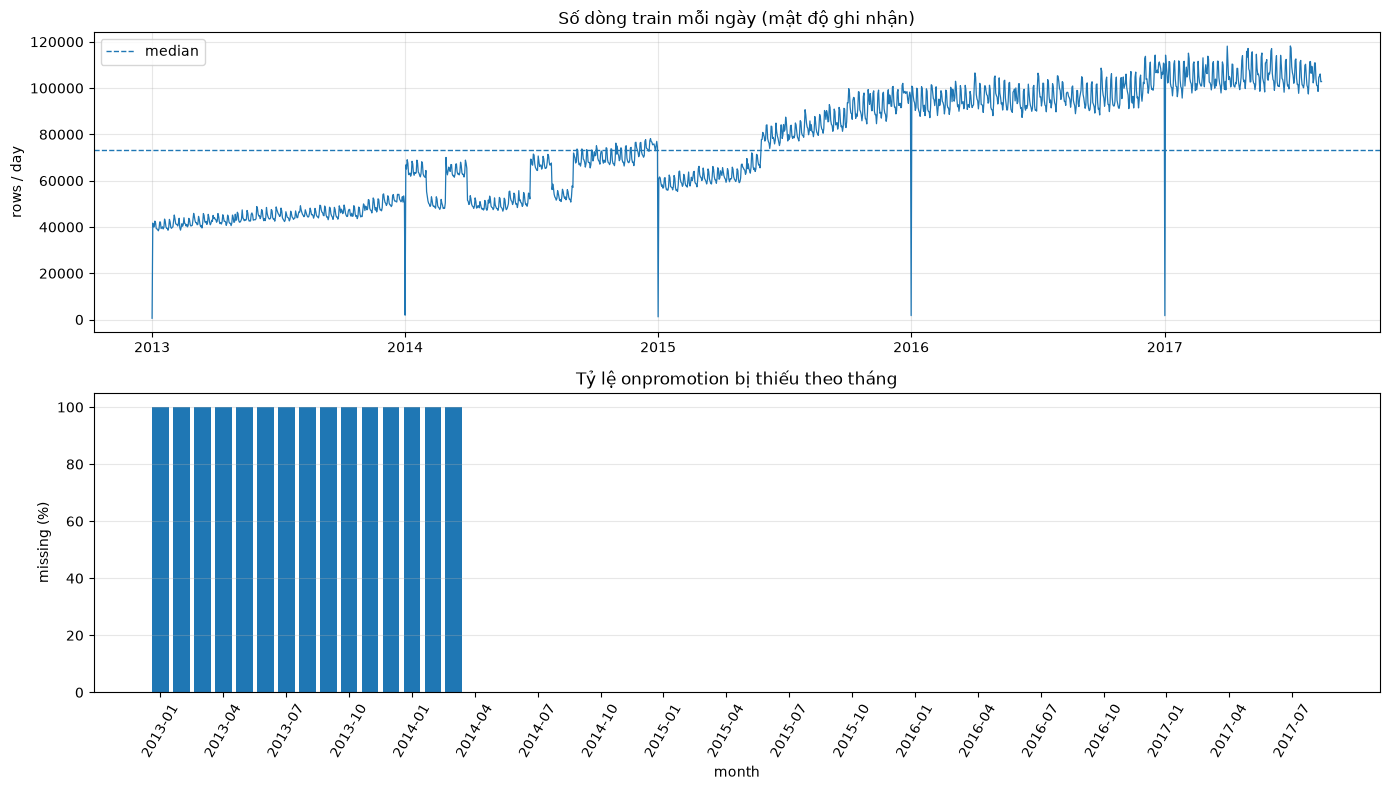

In [9]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=False)

axes[0].plot(daily_rows_df["date"], daily_rows_df["rows"], linewidth=0.9)
axes[0].axhline(median_rows, linestyle="--", linewidth=1, label="median")
axes[0].set_title("Số dòng train mỗi ngày (mật độ ghi nhận)")
axes[0].set_ylabel("rows / day")
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].bar(promo_month_df["month"], promo_month_df["missing_pct"])
axes[1].set_title("Tỷ lệ onpromotion bị thiếu theo tháng")
axes[1].set_ylabel("missing (%)")
axes[1].set_xlabel("month")
step = max(len(promo_month_df) // 15, 1)
axes[1].set_xticks(range(0, len(promo_month_df), step))
axes[1].set_xticklabels(promo_month_df["month"].iloc[::step], rotation=60)
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### Extended profile — interpretation

Đối chiếu với kết quả bạn đã có ở notebook 01 trên dữ liệu thật:

- **`onpromotion` thiếu có cấu trúc, không ngẫu nhiên.** Ở 01, bảng thiếu theo tháng cho thấy 100% dòng thiếu từ 2013-01 đến 2014-03 và 0% từ 2014-04. Cell trên xác minh lại bằng ngày chính xác (`last_missing_date` < `first_known_date`). Hệ quả: 17,26% thiếu là *chưa ghi nhận thông tin khuyến mãi*, không phải "không khuyến mãi". Do đó **không** impute `False`; notebook 03 cần cờ `promo_known` và cân nhắc giới hạn cửa sổ huấn luyện cho các mô hình dùng `onpromotion`.
- **Dòng bằng 0:** `unit_sales_zero_rows = 0` ở mục 4 nghĩa là train chỉ ghi các cặp-ngày *có bán*. Cặp-ngày không xuất hiện là "ngầm bằng 0" hoặc "không bán/không niêm yết"; không thể phân biệt hai trường hợp này chỉ từ train. Đây là lý do cleaning **không** thêm dòng (chính sách mục 2).
- **Outlier:** bảng `outlier_profile_df` và `extremes_df` chỉ định lượng. Các giá trị cực lớn/cực âm được **giữ nguyên**; nên xem `family` của chúng (hàng bán theo khối lượng thường có giá trị lớn/không nguyên) trước khi quyết định winsorize ở bước modeling.
- Nếu `id_span_equals_rows = False` hoặc `gaps > 0`: train không còn là chuỗi `id` liên tục (thông tin cần ghi nhận, chưa chắc là lỗi). Nếu `non_increasing_steps > 0`: `id` không duy nhất/không đơn điệu và sẽ chặn ở cổng bổ sung (6.1).

**[Kết quả sau khi chạy trên dữ liệu thật]**

- **`id`:** từ 0 đến 125.497.039, liên tục (không có khoảng trống), tăng nghiêm ngặt, không trùng; `id` của test (125.497.040 → 128.867.503) nối tiếp ngay sau train.
- **Mốc khuyến mãi chính xác:** ngày cuối còn thiếu là **2014-03-31**, ngày đầu có giá trị là **2014-04-01**; mọi dòng thiếu nằm trước mọi dòng có giá trị ⇒ thiếu có cấu trúc đã được xác minh bằng code.
- **Ngày mật độ thấp:** chỉ có 5 ngày, đều là 01/01 (578 đến 1.911 dòng so với trung vị 73.379 dòng/ngày). 4 ngày lịch vắng đều là 25/12.
- **Outlier `unit_sales`:** > 100: 626.348 dòng (0,50%); > 1.000: 3.204 (0,0026%); > 10.000: 35; < −100: 154; < −1.000: 20.
- **Giá trị không nguyên:** 8.191.095 dòng (6,53%), tập trung ở POULTRY (99,7%), MEATS (98,9%), PRODUCE (48,0%), SEAFOOD (34,2%), DELI (8,2%), PREPARED FOODS (6,3%), FROZEN FOODS (5,7%), BREAD/BAKERY (0,85%), GROCERY I (0,03%); các nhóm khác 0%. Đây là hàng bán theo khối lượng, nên không làm tròn.

## 5. Reference-table integrity & duplicate checks

Một số bảng có khóa duy nhất tự nhiên; riêng `holidays_events.csv` có thể có nhiều event cùng ngày, vì vậy không được coi `date` là khóa duy nhất của bảng này.


In [10]:
UNIQUE_REFERENCE_KEYS = {
    "stores.csv": ["store_nbr"],
    "items.csv": ["item_nbr"],
    "oil.csv": ["date"],
    "transactions.csv": ["date", "store_nbr"],
}

reference_duplicate_records = []
small_table_quality_records = []

for filename, df in small_raw.items():
    missing = df.isna().sum()
    for column, count in missing.items():
        small_table_quality_records.append({
            "file": filename,
            "column": column,
            "rows": len(df),
            "missing_count": int(count),
            "missing_pct": float(count / len(df) * 100) if len(df) else np.nan,
        })

    if filename in UNIQUE_REFERENCE_KEYS:
        key_columns = UNIQUE_REFERENCE_KEYS[filename]
        duplicate_rows = int(df.duplicated(subset=key_columns).sum())
        reference_duplicate_records.append({
            "file": filename,
            "key_columns": key_columns,
            "duplicate_rows": duplicate_rows,
        })

small_missingness_df = pd.DataFrame(small_table_quality_records)
reference_duplicates_df = pd.DataFrame(reference_duplicate_records)

display(small_missingness_df.sort_values(["file", "missing_count"], ascending=[True, False]))
display(reference_duplicates_df)
small_missingness_df.to_csv(REPORT_TABLE_DIR / "02_small_table_missingness.csv", index=False)
reference_duplicates_df.to_csv(REPORT_TABLE_DIR / "02_reference_key_duplicates.csv", index=False)


,file,column,rows,missing_count,missing_pct
11,holidays_events.csv,date,350,0,0.000000
12,holidays_events.csv,type,350,0,0.000000
13,holidays_events.csv,locale,350,0,0.000000
14,holidays_events.csv,locale_name,350,0,0.000000
15,holidays_events.csv,description,350,0,0.000000
16,holidays_events.csv,transferred,350,0,0.000000
5,items.csv,item_nbr,4100,0,0.000000
6,items.csv,family,4100,0,0.000000
7,items.csv,class,4100,0,0.000000
8,items.csv,perishable,4100,0,0.000000


,file,key_columns,duplicate_rows
0,stores.csv,[store_nbr],0
1,items.csv,[item_nbr],0
2,oil.csv,[date],0
3,transactions.csv,"[date, store_nbr]",0


### Reference-table decisions

- `stores.store_nbr`, `items.item_nbr`, `oil.date` và `(transactions.date, transactions.store_nbr)` được kỳ vọng duy nhất.
- Không áp đặt uniqueness cho `holidays_events.date`, vì một ngày có thể có nhiều event.
- Missing oil prices được giữ nguyên; không forward-fill/interpolate trong notebook cleaning.
- Nếu phát hiện duplicate trong bảng cần unique key, cần điều tra và quyết định riêng thay vì xóa dòng tự động.


### 5.1 Reference-table semantic checks

Mục 5 mới kiểm tra khóa duy nhất và missing. Các bảng tham chiếu còn có ràng buộc *ngữ nghĩa* ảnh hưởng đến cách join ở notebook 03. Cell dưới đây ghi từng kiểm tra với trạng thái `PASS / WARN / FAIL / INFO`. Chỉ `FAIL` mới chặn pipeline (ở 6.1); `WARN` và `INFO` là thông tin cho quyết định ở 03.

In [11]:
semantic_checks = []


def add_check(table, check, status, detail=""):
    semantic_checks.append({"table": table, "check": check, "status": status, "detail": detail})


# ---------------- stores
stores_df = small_raw["stores.csv"].copy()
city_state_counts = stores_df.groupby("city")["state"].nunique()
bad_cities = city_state_counts[city_state_counts > 1].index.tolist()
add_check("stores", "mỗi city thuộc đúng một state", "PASS" if not bad_cities else "WARN", f"city mâu thuẫn: {bad_cities}")
store_ids = sorted(pd.to_numeric(stores_df["store_nbr"]).astype(int))
add_check("stores", "store_nbr liên tục từ 1", "PASS" if store_ids == list(range(1, len(store_ids) + 1)) else "INFO", f"min={store_ids[0]}, max={store_ids[-1]}, n={len(store_ids)}")
add_check("stores", "type thuộc A–E", "PASS" if set(stores_df["type"].dropna().unique()) <= set("ABCDE") else "WARN", str(sorted(stores_df["type"].dropna().unique())))

# ---------------- items
items_df = small_raw["items.csv"].copy()
class_family_counts = items_df.groupby("class")["family"].nunique()
bad_classes = class_family_counts[class_family_counts > 1].index.tolist()
add_check("items", "mỗi class thuộc đúng một family", "PASS" if not bad_classes else "WARN", f"class thuộc nhiều family: {bad_classes[:10]}")
perishable_domain = set(pd.to_numeric(items_df["perishable"], errors="coerce").dropna().astype(int).unique())
add_check("items", "perishable chỉ nhận 0/1", "PASS" if perishable_domain <= {0, 1} else "FAIL", str(sorted(perishable_domain)))
add_check("items", "số family", "INFO", str(items_df["family"].nunique()))

# ---------------- oil
oil_df = small_raw["oil.csv"].copy()
oil_df["date"] = pd.to_datetime(oil_df["date"])
oil_price = pd.to_numeric(oil_df["dcoilwtico"], errors="coerce")
add_check("oil", "giá dầu > 0", "PASS" if (oil_price.dropna() > 0).all() else "FAIL", f"số giá trị <= 0: {int((oil_price.dropna() <= 0).sum())}")
daily_change = oil_price.dropna().pct_change().abs()
add_check("oil", "biến động ngày > 15% (gắn cờ, không sửa)", "INFO", f"{int((daily_change > 0.15).sum())} ngày")
business_days = pd.bdate_range(oil_df["date"].min(), oil_df["date"].max())
absent_business_days = business_days.difference(oil_df["date"])
add_check("oil", "ngày làm việc không có dòng nào", "INFO", f"{len(absent_business_days)} ngày")
add_check("oil", "dòng ở cuối tuần", "INFO", f"{int((oil_df['date'].dt.dayofweek >= 5).sum())} dòng")
add_check("oil", "giá thiếu (NaN) trong file", "INFO", f"{int(oil_price.isna().sum())} ({oil_price.isna().mean() * 100:.2f}%)")
train_last_day = pd.Timestamp(max(ext["daily_rows"]))
add_check("oil", "phủ đến hết ngày cuối của train", "PASS" if oil_df["date"].max() >= train_last_day else "WARN", f"oil max date = {oil_df['date'].max().date()}, train max date = {train_last_day.date()}")

# ---------------- holidays
hol_df = small_raw["holidays_events.csv"].copy()
hol_df["date"] = pd.to_datetime(hol_df["date"])
is_transferred = hol_df["transferred"].astype(str).str.strip().str.lower().eq("true")
n_transfer_rows = int((hol_df["type"].astype(str).str.strip() == "Transfer").sum())
add_check("holidays_events", "số dòng transferred=True bằng số dòng type=Transfer", "PASS" if int(is_transferred.sum()) == n_transfer_rows else "WARN",
          f"transferred=True: {int(is_transferred.sum())}, type=Transfer: {n_transfer_rows}")
add_check("holidays_events", "locale thuộc National/Regional/Local", "PASS" if set(hol_df["locale"].unique()) <= {"National", "Regional", "Local"} else "WARN", str(sorted(hol_df["locale"].unique())))
add_check("holidays_events", "National chỉ gắn với Ecuador", "PASS" if set(hol_df.loc[hol_df["locale"] == "National", "locale_name"].unique()) <= {"Ecuador"} else "WARN", "")

store_cities = set(stores_df["city"].astype(str).str.strip())
store_states = set(stores_df["state"].astype(str).str.strip())
local_unmatched = hol_df[(hol_df["locale"] == "Local") & ~hol_df["locale_name"].astype(str).str.strip().isin(store_cities)]
regional_unmatched = hol_df[(hol_df["locale"] == "Regional") & ~hol_df["locale_name"].astype(str).str.strip().isin(store_states)]
add_check("holidays_events", "Local khớp city của stores", "PASS" if local_unmatched.empty else "INFO", f"{len(local_unmatched)} dòng Local không có cửa hàng trong city đó (vô hại khi join)")
add_check("holidays_events", "Regional khớp state của stores", "PASS" if regional_unmatched.empty else "INFO", f"{len(regional_unmatched)} dòng Regional không có cửa hàng trong state đó")

same_place_day = int(hol_df.duplicated(subset=["date", "locale", "locale_name"], keep=False).sum())
add_check("holidays_events", "nhiều dòng cùng (date, locale, locale_name)", "WARN" if same_place_day else "PASS",
          f"{same_place_day} dòng — join phải tổng hợp trước để không nhân dòng train/test")

# ---------------- transactions
tx_df = small_raw["transactions.csv"].copy()
tx_values = pd.to_numeric(tx_df["transactions"], errors="coerce")
add_check("transactions", "transactions >= 0", "PASS" if (tx_values.dropna() >= 0).all() else "FAIL", f"min={tx_values.min()}, max={tx_values.max()}")
add_check("transactions", "transactions == 0", "INFO", f"{int((tx_values == 0).sum())} dòng")
tx_pairs = set(zip(tx_df["date"].astype(str), pd.to_numeric(tx_df["store_nbr"]).astype(int)))
train_store_days = ext["store_days"]
add_check("transactions", "store-day có bán hàng nhưng thiếu trong transactions", "WARN" if train_store_days - tx_pairs else "PASS", f"{len(train_store_days - tx_pairs):,} store-day")
add_check("transactions", "store-day có transactions nhưng không có trong train", "INFO" if tx_pairs - train_store_days else "PASS", f"{len(tx_pairs - train_store_days):,} store-day")
add_check("transactions", "độ phủ so với store-day của train", "INFO", f"{len(tx_pairs & train_store_days) / max(len(train_store_days), 1) * 100:.2f}%")

semantic_checks_df = pd.DataFrame(semantic_checks)
display(semantic_checks_df)
print(semantic_checks_df["status"].value_counts().to_string())
semantic_checks_df.to_csv(REPORT_TABLE_DIR / "02_reference_semantic_checks.csv", index=False)

,table,check,status,detail
0,stores,mỗi city thuộc đúng một state,PASS,city mâu thuẫn: []
1,stores,store_nbr liên tục từ 1,PASS,"min=1, max=54, n=54"
2,stores,type thuộc A–E,PASS,"['A', 'B', 'C', 'D', 'E']"
3,items,mỗi class thuộc đúng một family,PASS,class thuộc nhiều family: []
4,items,perishable chỉ nhận 0/1,PASS,"[np.int64(0), np.int64(1)]"
5,items,số family,INFO,33
6,oil,giá dầu > 0,PASS,số giá trị <= 0: 0
7,oil,"biến động ngày > 15% (gắn cờ, không sửa)",INFO,0 ngày
8,oil,ngày làm việc không có dòng nào,INFO,0 ngày
9,oil,dòng ở cuối tuần,INFO,0 dòng


status
PASS    14
INFO     7
WARN     2


**Cách dùng kết quả 5.1 ở notebook 03:**

- `holidays_events`: nếu có nhiều dòng cùng `(date, locale, locale_name)` thì phải gom (ví dụ lấy cờ "có lễ" và loại lễ ưu tiên) **trước khi** merge, nếu không số dòng train/test sẽ tăng ngoài ý muốn.
- Dòng `transferred = True` là ngày lễ danh nghĩa đã được dời; ngày nghỉ thực sự là dòng `type = Transfer`.
- `oil`: thiếu giá ở ngày làm việc và vắng mặt vào cuối tuần là hai hiện tượng khác nhau; cả hai chỉ điền bằng giá trị *trước đó* (không dùng giá trị tương lai) để tránh leakage.
- `transactions`: store-day có bán hàng nhưng thiếu transactions cần một cờ riêng thay vì điền 0.

## 6. Validation gate — có đủ điều kiện làm sạch không?

Trước khi ghi đầu ra, xác nhận không có vấn đề cấu trúc không thể xử lý an toàn bằng chuẩn hóa. Notebook không tự drop hoặc impute để biến validation fail thành pass.


In [12]:
blocking_issues = []

# Required schema
if (schema_df["status"] == "MISSING_REQUIRED").any():
    blocking_issues.append("Required schema columns are missing.")

# Large-table structural validity and referential integrity
for filename, profile in large_profiles.items():
    for field in ["invalid_date_rows", "invalid_store_nbr_rows", "invalid_item_nbr_rows",
                  "nonpositive_store_nbr_rows", "nonpositive_item_nbr_rows",
                  "store_reference_mismatch_rows", "item_reference_mismatch_rows",
                  "onpromotion_unrecognized_rows"]:
        value = int(profile.get(field, 0) or 0)
        if value > 0:
            blocking_issues.append(f"{filename}: {field}={value}")

    if int(profile.get("invalid_id_rows", 0) or 0) > 0:
        blocking_issues.append(f"{filename}: invalid_id_rows={profile['invalid_id_rows']}")

    if filename == "train.csv":
        if int(profile.get("unit_sales_nonnumeric_rows", 0) or 0) > 0:
            blocking_issues.append(
                f"train.csv: unit_sales_nonnumeric_rows={profile['unit_sales_nonnumeric_rows']}"
            )
        if int(profile["missing_by_column"].get("unit_sales", 0)) > 0:
            blocking_issues.append(
                f"train.csv: unit_sales missing={profile['missing_by_column']['unit_sales']}"
            )

    if not profile["business_key_order_is_monotonic"]:
        blocking_issues.append(
            f"{filename}: business key stream is not monotonic; chunk-only duplicate check cannot prove global uniqueness."
        )
    elif int(profile.get("business_key_duplicate_rows_total_if_sorted", 0) or 0) > 0:
        blocking_issues.append(
            f"{filename}: duplicate business-key rows={profile['business_key_duplicate_rows_total_if_sorted']}"
        )

if not reference_duplicates_df.empty:
    duplicates_found = reference_duplicates_df[reference_duplicates_df["duplicate_rows"] > 0]
    for _, row in duplicates_found.iterrows():
        blocking_issues.append(
            f"{row['file']}: duplicate rows for key {row['key_columns']}={row['duplicate_rows']}"
        )

if blocking_issues:
    display(pd.DataFrame({"blocking_issue": blocking_issues}))
    raise RuntimeError(
        "Validation gate failed. Không ghi dữ liệu cleaned. Xử lý từng vấn đề có căn cứ rồi chạy lại notebook."
    )
else:
    print("VALIDATION GATE PASSED: có thể chuyển sang chuẩn hóa và ghi dữ liệu.")


VALIDATION GATE PASSED: có thể chuyển sang chuẩn hóa và ghi dữ liệu.


### Gate interpretation

Đi qua gate không có nghĩa dữ liệu hoàn toàn không còn missing values. Nó nghĩa là các điều kiện cấu trúc cần thiết để chuẩn hóa an toàn đã đạt: schema bắt buộc có mặt, ngày và khóa hợp lệ, quan hệ store/item hợp lệ, token promotion hiểu được, khóa nghiệp vụ có thể kiểm tra toàn cục theo thứ tự dữ liệu và không phát hiện duplicate theo khóa.

Các missing values có chủ đích/đang cần quyết định (`onpromotion`, oil price) được giữ lại và đưa vào báo cáo, không bị che đi bằng imputation mặc định.


### 6.1 Supplementary gate — test, sample_submission và tính toàn vẹn bổ sung

Cổng ở mục 6 chưa kiểm tra `sample_submission.csv` (không có trong `EXPECTED_COLUMNS`), tính duy nhất của `id`, và cấu trúc của `test.csv`. Đây là những lỗi gây hỏng file nộp bài một cách âm thầm. Cổng bổ sung chạy **trước khi ghi output** (mục 8).

In [14]:
supp_checks = []


def add_gate(check, status, detail=""):
    supp_checks.append({"check": check, "status": status, "detail": detail})


sub_df = pd.read_csv(RAW_DIR / "sample_submission.csv")
test_df = pd.read_csv(RAW_DIR / "test.csv", usecols=["id", "date", "store_nbr", "item_nbr"])
test_df["date"] = pd.to_datetime(test_df["date"])

# ---- sample_submission
add_gate("sample_submission có đúng cột [id, unit_sales]", "PASS" if list(sub_df.columns) == ["id", "unit_sales"] else "BLOCK", str(list(sub_df.columns)))
add_gate("sample_submission: id duy nhất", "PASS" if sub_df["id"].is_unique else "BLOCK", f"duplicates={int(sub_df['id'].duplicated().sum())}")
same_set = set(sub_df["id"]) == set(test_df["id"])
add_gate("sample_submission.id trùng tập id của test", "PASS" if same_set else "BLOCK", f"submission={len(sub_df):,}, test={len(test_df):,}")
add_gate("sample_submission.id cùng thứ tự với test", "PASS" if (same_set and sub_df["id"].to_numpy().tolist() == test_df["id"].to_numpy().tolist()) else "WARN", "")

# ---- test structure
add_gate("test: id duy nhất", "PASS" if test_df["id"].is_unique else "BLOCK", "")
add_gate("test: id liên tục", "PASS" if (test_df["id"].max() - test_df["id"].min() + 1) == len(test_df) else "WARN", f"min={test_df['id'].min()}, max={test_df['id'].max()}")
add_gate("test.id bắt đầu ngay sau train.id", "PASS" if int(test_df["id"].min()) == ext["id_max"] + 1 else "WARN", f"train max id={ext['id_max']}, test min id={int(test_df['id'].min())}")

test_days = test_df["date"].nunique()
test_contiguous = (test_df["date"].max() - test_df["date"].min()).days + 1 == test_days
add_gate("test: các ngày liên tiếp", "PASS" if test_contiguous else "WARN", f"{test_days} ngày: {test_df['date'].min().date()} → {test_df['date'].max().date()}")

train_last_date = pd.Timestamp(max(ext["daily_rows"]))
add_gate("test bắt đầu sau ngày cuối của train (không chồng lấn)", "PASS" if test_df["date"].min() > train_last_date else "BLOCK", f"train max={train_last_date.date()}")

pair_counts = test_df.groupby(["store_nbr", "item_nbr"]).size()
add_gate("test là lưới đầy đủ cặp × ngày", "PASS" if pair_counts.nunique() == 1 and int(pair_counts.iloc[0]) == test_days else "WARN",
         f"cặp={len(pair_counts):,}, ngày={test_days}, dòng/cặp: {sorted(pair_counts.unique().tolist())[:5]}")
add_gate("test: store_nbr ⊆ stores.csv", "PASS" if set(test_df["store_nbr"]) <= stores_ref else "BLOCK", "")
add_gate("test: item_nbr ⊆ items.csv", "PASS" if set(test_df["item_nbr"]) <= items_ref else "BLOCK", "")

# ---- train id integrity (từ extended profile)
add_gate("train: id tăng nghiêm ngặt (duy nhất)", "PASS" if ext["id_non_increasing"] == 0 else "BLOCK", f"bước không tăng={ext['id_non_increasing']}")
add_gate("train: id liên tục", "PASS" if ext["id_gaps"] == 0 else "WARN", f"số khoảng trống={ext['id_gaps']}")

# ---- thiếu có cấu trúc của onpromotion
add_gate("train: onpromotion thiếu có cấu trúc theo thời gian", "INFO" if structural_missing else "WARN",
         f"last_missing={ext['last_missing_date']}, first_known={ext['first_known_date']}")
add_gate("test: onpromotion không thiếu", "PASS" if large_profiles["test.csv"]["missing_by_column"].get("onpromotion", 0) == 0 else "WARN", "")

# ---- ngữ nghĩa bảng tham chiếu
semantic_fail = semantic_checks_df[semantic_checks_df["status"] == "FAIL"]
add_gate("bảng tham chiếu: không có kiểm tra ngữ nghĩa FAIL", "PASS" if semantic_fail.empty else "BLOCK", f"{len(semantic_fail)} FAIL")

supp_gate_df = pd.DataFrame(supp_checks)
display(supp_gate_df)
supp_gate_df.to_csv(REPORT_TABLE_DIR / "02_supplementary_gate.csv", index=False)

supp_blocking = supp_gate_df[supp_gate_df["status"] == "BLOCK"]
if not supp_blocking.empty:
    raise RuntimeError("Supplementary gate failed. Không ghi dữ liệu cleaned:\n" + supp_blocking.to_string(index=False))
print("SUPPLEMENTARY GATE PASSED. WARN/INFO ở trên là thông tin cho notebook 03, không chặn pipeline.")

del sub_df, test_df, pair_counts

,check,status,detail
0,"sample_submission có đúng cột [id, unit_sales]",PASS,"['id', 'unit_sales']"
1,sample_submission: id duy nhất,PASS,duplicates=0
2,sample_submission.id trùng tập id của test,PASS,"submission=3,370,464, test=3,370,464"
3,sample_submission.id cùng thứ tự với test,PASS,
4,test: id duy nhất,PASS,
5,test: id liên tục,PASS,"min=125497040, max=128867503"
6,test.id bắt đầu ngay sau train.id,PASS,"train max id=125497039, test min id=125497040"
7,test: các ngày liên tiếp,PASS,16 ngày: 2017-08-16 → 2017-08-31
8,test bắt đầu sau ngày cuối của train (không ch...,PASS,train max=2017-08-15
9,test là lưới đầy đủ cặp × ngày,PASS,"cặp=210,654, ngày=16, dòng/cặp: [16]"


SUPPLEMENTARY GATE PASSED. WARN/INFO ở trên là thông tin cho notebook 03, không chặn pipeline.


## 7. Transform helpers — normalize without dropping rows

Các hàm dưới đây không lọc dòng. Chúng chỉ parse ngày, chuẩn hóa kiểu khóa và chuyển `onpromotion` về Boolean nullable. Bản ghi có promotion missing vẫn còn missing.


In [15]:
def normalize_large_chunk(chunk: pd.DataFrame, filename: str) -> pd.DataFrame:
    out = chunk.copy()

    out["date"] = pd.to_datetime(out["date"], errors="raise")
    out["store_nbr"] = pd.to_numeric(out["store_nbr"], errors="raise").astype("int32")
    out["item_nbr"] = pd.to_numeric(out["item_nbr"], errors="raise").astype("int32")

    if "id" in out.columns:
        out["id"] = pd.to_numeric(out["id"], errors="raise").astype("int64")

    if "unit_sales" in out.columns:
        # Preserve values, including negative unit sales; no rounding or row filtering.
        out["unit_sales"] = pd.to_numeric(out["unit_sales"], errors="raise").astype("float64")

    promotion, unknown = parse_nullable_boolean(out["onpromotion"])
    if int(unknown.sum()) > 0:
        raise ValueError(f"{filename}: found unrecognized onpromotion tokens during transform.")
    out["onpromotion"] = promotion

    return out


def normalize_small_table(filename: str, frame: pd.DataFrame) -> pd.DataFrame:
    out = frame.copy()

    # Trim whitespace for string-like columns without changing their semantic values.
    for column in out.select_dtypes(include=["object", "string"]).columns:
        out[column] = out[column].astype("string").str.strip()

    if "date" in out.columns:
        out["date"] = pd.to_datetime(out["date"], errors="raise")

    if "store_nbr" in out.columns:
        out["store_nbr"] = pd.to_numeric(out["store_nbr"], errors="raise").astype("int32")
    if "item_nbr" in out.columns:
        out["item_nbr"] = pd.to_numeric(out["item_nbr"], errors="raise").astype("int32")

    if filename == "oil.csv":
        out["dcoilwtico"] = pd.to_numeric(out["dcoilwtico"], errors="raise")
    if filename == "transactions.csv":
        out["transactions"] = pd.to_numeric(out["transactions"], errors="raise")

    return out


def write_frame(frame: pd.DataFrame, output_path: Path):
    # Write one small table using the selected output format.
    if OUTPUT_FORMAT == "parquet":
        frame.to_parquet(output_path, index=False, compression="snappy")
    else:
        frame.to_csv(output_path, index=False)


## 8. Write cleaned train/test in chunks

Mỗi file được ghi ra file tạm trước. Chỉ sau khi ghi hết các chunks thành công mới thay thế tên đầu ra chính. Như vậy nếu lỗi giữa chừng, file đầu ra cũ không bị thay bằng một file viết dở.


In [16]:
def clean_large_file(filename: str, output_stem: str):
    input_path = RAW_DIR / filename
    output_path = PROCESSED_DIR / f"{output_stem}_cleaned.{OUTPUT_FORMAT}"
    temp_path = PROCESSED_DIR / f".{output_stem}_cleaned.tmp.{OUTPUT_FORMAT}"

    if temp_path.exists():
        temp_path.unlink()

    row_count = 0
    output_missing_promotion = 0
    output_negative_target = 0
    parquet_writer = None
    first_csv_chunk = True
    start = time.time()

    try:
        for chunk in pd.read_csv(input_path, chunksize=CHUNK_SIZE, low_memory=False):
            cleaned = normalize_large_chunk(chunk, filename)
            row_count += len(cleaned)
            output_missing_promotion += int(cleaned["onpromotion"].isna().sum())
            if "unit_sales" in cleaned.columns:
                output_negative_target += int((cleaned["unit_sales"] < 0).sum())

            if OUTPUT_FORMAT == "parquet":
                table = pa.Table.from_pandas(cleaned, preserve_index=False)
                if parquet_writer is None:
                    parquet_writer = pq.ParquetWriter(
                        temp_path, table.schema, compression="snappy"
                    )
                else:
                    table = pa.Table.from_pandas(
                        cleaned, schema=parquet_writer.schema, preserve_index=False
                    )
                parquet_writer.write_table(table, row_group_size=CHUNK_SIZE)
            else:
                cleaned.to_csv(
                    temp_path,
                    mode="w" if first_csv_chunk else "a",
                    header=first_csv_chunk,
                    index=False,
                )
                first_csv_chunk = False

        if parquet_writer is not None:
            parquet_writer.close()
            parquet_writer = None

        if not temp_path.exists():
            raise RuntimeError(f"No output was produced for {filename}.")

        os.replace(temp_path, output_path)
    except Exception:
        if parquet_writer is not None:
            parquet_writer.close()
        if temp_path.exists():
            temp_path.unlink()
        raise

    result = {
        "input_file": filename,
        "output_file": str(output_path.relative_to(PROJECT_ROOT)),
        "rows_written": row_count,
        "missing_onpromotion_preserved": output_missing_promotion,
        "negative_unit_sales_preserved": output_negative_target if filename == "train.csv" else None,
        "output_size_mb": output_path.stat().st_size / (1024**2),
        "elapsed_minutes": (time.time() - start) / 60,
    }
    return result


large_write_results = []
for filename, output_stem in [("train.csv", "train"), ("test.csv", "test")]:
    print(f"Cleaning/normalizing {filename} ...")
    result = clean_large_file(filename, output_stem)
    large_write_results.append(result)
    display(pd.DataFrame([result]))


Cleaning/normalizing train.csv ...


,input_file,output_file,rows_written,missing_onpromotion_preserved,negative_unit_sales_preserved,output_size_mb,elapsed_minutes
0,train.csv,data/processed/train_cleaned.parquet,125497040,21657651,7795,1102.275264,5.461464


Cleaning/normalizing test.csv ...


,input_file,output_file,rows_written,missing_onpromotion_preserved,negative_unit_sales_preserved,output_size_mb,elapsed_minutes
0,test.csv,data/processed/test_cleaned.parquet,3370464,0,None,25.034229,0.138324


### Large-table transformation — interpretation

- Số dòng được giữ nguyên; không có `dropna`, filtering hoặc deduplication.
- `unit_sales` âm vẫn có trong đầu ra và được đếm để kiểm tra việc bảo toàn.
- `onpromotion` được chuẩn hóa thành kiểu Boolean nullable khi dùng Parquet; ở CSV, giá trị được ghi thành `True`/`False` và ô trống cho missing.
- Output chỉ chứa dữ liệu dẫn xuất trong `data/processed/`; raw files không bị thay đổi.


## 9. Clean small reference tables

Các bảng nhỏ được chuẩn hóa ngày, trim whitespace của các cột text và ép kiểu cho các khóa số. Không loại duplicate, không fill missing oil price và không tự gộp nhiều holiday cùng ngày.


In [17]:
small_write_results = []
for filename, frame in small_raw.items():
    cleaned_small = normalize_small_table(filename, frame)
    output_stem = filename.removesuffix(".csv")
    output_path = PROCESSED_DIR / f"{output_stem}_cleaned.{OUTPUT_FORMAT}"
    write_frame(cleaned_small, output_path)
    small_write_results.append({
        "input_file": filename,
        "output_file": str(output_path.relative_to(PROJECT_ROOT)),
        "rows_input": len(frame),
        "rows_written": len(cleaned_small),
        "output_size_mb": output_path.stat().st_size / (1024**2),
    })

display(pd.DataFrame(small_write_results))


,input_file,output_file,rows_input,rows_written,output_size_mb
0,stores.csv,data/processed/stores_cleaned.parquet,54,54,0.003917
1,items.csv,data/processed/items_cleaned.parquet,4100,4100,0.033337
2,oil.csv,data/processed/oil_cleaned.parquet,1218,1218,0.017352
3,holidays_events.csv,data/processed/holidays_events_cleaned.parquet,350,350,0.008315
4,transactions.csv,data/processed/transactions_cleaned.parquet,83488,83488,0.170516


## 10. Output validation

Kiểm tra nhanh đầu ra sau khi ghi:

1. Các file đầu ra tồn tại và mở được.
2. Số dòng đầu ra bằng số dòng đầu vào.
3. Schema đầu ra vẫn giữ các cột gốc (không có cột nào bị âm thầm bỏ).
4. Missing promotion và giá trị target âm đã thống kê khi ghi.

Với Parquet, số dòng được đọc từ metadata; với CSV, đếm dòng theo chunks.


In [18]:
def output_path_for(input_filename: str) -> Path:
    return PROCESSED_DIR / f"{input_filename.removesuffix('.csv')}_cleaned.{OUTPUT_FORMAT}"


def count_output_rows(path: Path) -> int:
    if OUTPUT_FORMAT == "parquet":
        return int(pq.ParquetFile(path).metadata.num_rows)
    count = 0
    for chunk in pd.read_csv(path, chunksize=CHUNK_SIZE, low_memory=False):
        count += len(chunk)
    return count


expected_row_counts = {
    filename: large_profiles[filename]["rows"] for filename in ["train.csv", "test.csv"]
}
expected_row_counts.update({filename: len(frame) for filename, frame in small_raw.items()})

output_validation_records = []
all_input_files = ["train.csv", "test.csv", *SMALL_FILES]
for filename in all_input_files:
    output_path = output_path_for(filename)
    if not output_path.exists():
        raise FileNotFoundError(f"Missing output: {output_path}")

    output_rows = count_output_rows(output_path)
    input_rows = int(expected_row_counts[filename])
    if OUTPUT_FORMAT == "parquet":
        parquet_file = pq.ParquetFile(output_path)
        first_batch = next(parquet_file.iter_batches(batch_size=5), None)
        sample = (
            first_batch.to_pandas()
            if first_batch is not None
            else pd.DataFrame(columns=parquet_file.schema_arrow.names)
        )
    else:
        sample = pd.read_csv(output_path, nrows=5)

    missing_columns = sorted(set(EXPECTED_COLUMNS[filename]) - set(sample.columns))
    status = "OK" if (output_rows == input_rows and not missing_columns) else "CHECK_FAILED"
    output_validation_records.append({
        "input_file": filename,
        "output_file": str(output_path.relative_to(PROJECT_ROOT)),
        "input_rows": input_rows,
        "output_rows": output_rows,
        "row_count_match": output_rows == input_rows,
        "missing_expected_columns": missing_columns,
        "status": status,
        "output_size_mb": output_path.stat().st_size / (1024**2),
    })

output_validation_df = pd.DataFrame(output_validation_records)
display(output_validation_df)
output_validation_df.to_csv(REPORT_TABLE_DIR / "02_output_validation.csv", index=False)

if (output_validation_df["status"] != "OK").any():
    raise RuntimeError("Output validation failed. Review reports/table/02_output_validation.csv.")


,input_file,output_file,input_rows,output_rows,row_count_match,missing_expected_columns,status,output_size_mb
0,train.csv,data/processed/train_cleaned.parquet,125497040,125497040,True,[],OK,1102.275264
1,test.csv,data/processed/test_cleaned.parquet,3370464,3370464,True,[],OK,25.034229
2,stores.csv,data/processed/stores_cleaned.parquet,54,54,True,[],OK,0.003917
3,items.csv,data/processed/items_cleaned.parquet,4100,4100,True,[],OK,0.033337
4,oil.csv,data/processed/oil_cleaned.parquet,1218,1218,True,[],OK,0.017352
5,holidays_events.csv,data/processed/holidays_events_cleaned.parquet,350,350,True,[],OK,0.008315
6,transactions.csv,data/processed/transactions_cleaned.parquet,83488,83488,True,[],OK,0.170516


### Output validation — interpretation

`row_count_match = True` cho mọi file chứng minh rằng bước cleaning này không loại hoặc thêm record. Đây là điều có chủ đích ở bước đầu: phát hiện và chuẩn hóa trước, không tự ý thay đổi dữ liệu chỉ để làm bảng trông sạch hơn.


### 10.1 Reconciliation — đối soát giá trị raw và processed

Mục 10 chỉ chứng minh *số dòng* và *tên cột* khớp. Một phép chuẩn hóa vẫn có thể làm hỏng giá trị mà số dòng không đổi (ví dụ ép dtype làm tròn `unit_sales`, parse sai ngày, nhầm `True/False`). Cell này so sánh các **tổng kiểm (checksum) tổng hợp** giữa raw và processed:

- tổng `unit_sales` (float64), số dòng âm;
- tổng `id`, `store_nbr`, `item_nbr` (checksum số nguyên);
- ngày nhỏ nhất/lớn nhất;
- số dòng `onpromotion` True / False / thiếu.

Sau đó kiểm tra schema đầu ra và băm lại các file raw để so với manifest ở 3.1.

In [19]:
def new_stats():
    return {"rows": 0, "sum_unit_sales": 0.0, "negative_rows": 0, "sum_id": 0, "sum_store": 0, "sum_item": 0,
            "min_date": None, "max_date": None, "promo_true": 0, "promo_false": 0, "promo_missing": 0}


def update_stats(stats, frame, promo, dates):
    stats["rows"] += len(frame)
    stats["sum_id"] += int(frame["id"].to_numpy(dtype="int64").sum())
    stats["sum_store"] += int(frame["store_nbr"].to_numpy(dtype="int64").sum())
    stats["sum_item"] += int(frame["item_nbr"].to_numpy(dtype="int64").sum())
    if "unit_sales" in frame.columns:
        values = frame["unit_sales"].to_numpy(dtype="float64")
        stats["sum_unit_sales"] += float(np.sum(values, dtype=np.float64))
        stats["negative_rows"] += int((values < 0).sum())
    stats["promo_missing"] += int(promo.isna().sum())
    stats["promo_true"] += int(promo.fillna(False).to_numpy(dtype=bool)[~promo.isna().to_numpy()].sum())
    stats["promo_false"] += int((~promo.fillna(True).to_numpy(dtype=bool)).sum())
    lo, hi = dates.min(), dates.max()
    stats["min_date"] = lo if stats["min_date"] is None else min(stats["min_date"], lo)
    stats["max_date"] = hi if stats["max_date"] is None else max(stats["max_date"], hi)


def raw_stats(filename):
    stats = new_stats()
    columns = [c for c in ["id", "date", "store_nbr", "item_nbr", "unit_sales", "onpromotion"] if c in pd.read_csv(RAW_DIR / filename, nrows=0).columns]
    for chunk in pd.read_csv(RAW_DIR / filename, usecols=columns, chunksize=EXT_CHUNK_SIZE, low_memory=False):
        promo, _ = parse_nullable_boolean(chunk["onpromotion"])
        update_stats(stats, chunk, promo, pd.to_datetime(chunk["date"]))
    return stats


def cleaned_stats(path, columns):
    stats = new_stats()
    if OUTPUT_FORMAT == "parquet":
        for batch in pq.ParquetFile(path).iter_batches(batch_size=EXT_CHUNK_SIZE, columns=columns):
            frame = batch.to_pandas()
            update_stats(stats, frame, frame["onpromotion"].astype("boolean"), pd.to_datetime(frame["date"]))
    else:
        for frame in pd.read_csv(path, usecols=columns, chunksize=EXT_CHUNK_SIZE, low_memory=False):
            promo, _ = parse_nullable_boolean(frame["onpromotion"])
            update_stats(stats, frame, promo, pd.to_datetime(frame["date"]))
    return stats


reconciliation_records = []
for filename in ["train.csv", "test.csv"]:
    cols = [c for c in ["id", "date", "store_nbr", "item_nbr", "unit_sales", "onpromotion"] if c in pd.read_csv(RAW_DIR / filename, nrows=0).columns]
    raw_s = raw_stats(filename)
    clean_s = cleaned_stats(output_path_for(filename), cols)
    for metric in raw_s:
        a, b = raw_s[metric], clean_s[metric]
        if metric == "sum_unit_sales":
            ok = math.isclose(a, b, rel_tol=1e-12, abs_tol=1e-6)
        else:
            ok = (a == b)
        reconciliation_records.append({"file": filename, "metric": metric, "raw": a, "processed": b, "match": bool(ok)})

reconciliation_df = pd.DataFrame(reconciliation_records)
display(reconciliation_df)
reconciliation_df.to_csv(REPORT_TABLE_DIR / "02_reconciliation.csv", index=False)
if not reconciliation_df["match"].all():
    raise RuntimeError("Reconciliation failed: giá trị raw và processed không khớp. Xem reports/table/02_reconciliation.csv")
print("RECONCILIATION PASSED: các checksum tổng hợp của raw và processed khớp nhau.")

,file,metric,raw,processed,match
0,train.csv,rows,125497040,125497040,True
1,train.csv,sum_unit_sales,1073610268.7878,1073610268.7878,True
2,train.csv,negative_rows,7795,7795,True
3,train.csv,sum_id,7874753461632280,7874753461632280,True
4,train.csv,sum_store,3446723247,3446723247,True
5,train.csv,sum_item,122079649269994,122079649269994,True
6,train.csv,min_date,2013-01-01 00:00:00,2013-01-01 00:00:00,True
7,train.csv,max_date,2017-08-15 00:00:00,2017-08-15 00:00:00,True
8,train.csv,promo_true,7810622,7810622,True
9,train.csv,promo_false,96028767,96028767,True


RECONCILIATION PASSED: các checksum tổng hợp của raw và processed khớp nhau.


In [20]:
# ---- schema đầu ra (chỉ kiểm tra được đầy đủ với Parquet)
EXPECTED_OUTPUT_TYPES = {
    "train.csv": {"id": "int64", "date": "timestamp", "store_nbr": "int32", "item_nbr": "int32", "unit_sales": "double", "onpromotion": "bool"},
    "test.csv": {"id": "int64", "date": "timestamp", "store_nbr": "int32", "item_nbr": "int32", "onpromotion": "bool"},
    "oil.csv": {"date": "timestamp", "dcoilwtico": "double"},
    "stores.csv": {"store_nbr": "int32"},
    "items.csv": {"item_nbr": "int32"},
    "transactions.csv": {"date": "timestamp", "store_nbr": "int32"},
    "holidays_events.csv": {"date": "timestamp"},
}

schema_records = []
if OUTPUT_FORMAT == "parquet":
    for filename, expected in EXPECTED_OUTPUT_TYPES.items():
        arrow_schema = pq.read_schema(output_path_for(filename))
        for column, expected_type in expected.items():
            actual_type = str(arrow_schema.field(column).type)
            schema_records.append({
                "file": filename, "column": column, "expected": expected_type, "actual": actual_type,
                "ok": actual_type.startswith(expected_type),
            })
    output_schema_df = pd.DataFrame(schema_records)
    display(output_schema_df)
    output_schema_df.to_csv(REPORT_TABLE_DIR / "02_output_schema.csv", index=False)
    if not output_schema_df["ok"].all():
        raise RuntimeError("Output schema không khớp kỳ vọng. Xem reports/table/02_output_schema.csv")
    print("OUTPUT SCHEMA OK")
else:
    output_schema_df = pd.DataFrame()
    print("Output là CSV: bỏ qua kiểm tra kiểu Arrow (CSV không lưu kiểu dữ liệu).")

# ---- raw có bị thay đổi không?
raw_manifest_after = fingerprint_raw_dir()
raw_changed = [n for n in raw_manifest_before if raw_manifest_before[n] != raw_manifest_after.get(n)]
RAW_UNCHANGED = not raw_changed
print("Raw files không thay đổi:", RAW_UNCHANGED, "" if RAW_UNCHANGED else f"— thay đổi: {raw_changed}")
if not RAW_UNCHANGED:
    raise RuntimeError(f"Raw files đã bị thay đổi trong lúc chạy notebook: {raw_changed}")

,file,column,expected,actual,ok
0,train.csv,id,int64,int64,True
1,train.csv,date,timestamp,timestamp[us],True
2,train.csv,store_nbr,int32,int32,True
3,train.csv,item_nbr,int32,int32,True
4,train.csv,unit_sales,double,double,True
5,train.csv,onpromotion,bool,bool,True
6,test.csv,id,int64,int64,True
7,test.csv,date,timestamp,timestamp[us],True
8,test.csv,store_nbr,int32,int32,True
9,test.csv,item_nbr,int32,int32,True


OUTPUT SCHEMA OK
Raw files không thay đổi: True 


## 11. Save consolidated cleaning report

Báo cáo JSON lưu lại policy, profile raw, kết quả ghi và kiểm tra output để có thể tra cứu mà không phải suy luận từ từng cell.


In [21]:
def make_json_safe(value):
    if isinstance(value, dict):
        return {str(k): make_json_safe(v) for k, v in value.items()}
    if isinstance(value, list):
        return [make_json_safe(v) for v in value]
    if isinstance(value, (np.integer,)):
        return int(value)
    if isinstance(value, (np.floating,)):
        return float(value)
    if isinstance(value, (np.bool_,)):
        return bool(value)
    if pd.isna(value) if not isinstance(value, (dict, list, tuple)) else False:
        return None
    return value


cleaning_report = {
    "notebook": "02_data_cleaning.ipynb",
    "project_root": str(PROJECT_ROOT),
    "output_format": OUTPUT_FORMAT,
    "chunk_size": CHUNK_SIZE,
    "policies": {
        "raw_files_modified": False,
        "rows_dropped": False,
        "duplicates_deleted": False,
        "negative_unit_sales_deleted": False,
        "onpromotion_missing_imputed": False,
        "oil_missing_imputed": False,
        "date_gaps_filled": False,
        "date_normalization": "datetime",
        "onpromotion_normalization": "nullable boolean; missing preserved",
    },
    "schema_validation": schema_records,
    "raw_large_table_profiles": large_profiles,
    "reference_key_duplicates": reference_duplicate_records,
    "large_table_write_results": large_write_results,
    "small_table_write_results": small_write_results,
    "output_validation": output_validation_records,
}

report_path = REPORT_DIR / "02_cleaning_report.json"
with report_path.open("w", encoding="utf-8") as file:
    json.dump(make_json_safe(cleaning_report), file, ensure_ascii=False, indent=2)

print(f"Cleaning report saved: {report_path.relative_to(PROJECT_ROOT)}")


Cleaning report saved: reports/02_cleaning_report.json


## 12. Final checklist & handoff to `03_feature_engineering`

Sau khi chạy hết notebook, xác nhận:

- [ ] Schema bắt buộc đã xác nhận; cột extra (nếu có) đã được xem xét.
- [ ] Không có lỗi ngày/khóa/kiểu dữ liệu không giải thích được.
- [ ] Kiểm tra duplicate business key đã có kết luận rõ ràng.
- [ ] Số dòng raw và processed khớp nhau ở tất cả file.
- [ ] Raw files vẫn nguyên vẹn.
- [ ] Missing `onpromotion` và `oil.dcoilwtico` được giữ lại, có báo cáo.
- [ ] Negative `unit_sales` không bị xóa tự động.
- [ ] Các bảng báo cáo đã lưu trong `reports/table/` và `reports/02_cleaning_report.json`.

### Quyết định chuyển tiếp

`02_data_cleaning` chỉ chuẩn hóa và xác minh dữ liệu; không thực hiện split ngẫu nhiên, không tạo lag/rolling và không impute theo cách có thể gây leakage. Sang `03_feature_engineering`, P sẽ quyết định rõ chính sách imputing theo thời gian, tạo calendar features, promotion/oil features và chiến lược feature cho forecasting.

**Đầu ra chính:** `data/processed/*_cleaned.<parquet|csv>`.


## 12.1 Runtime checklist (tự động)

Danh sách kiểm tra thủ công ở trên được đánh giá lại bằng code, dựa trên biến của các cell đã chạy, để không phụ thuộc vào việc tick tay.

In [22]:
checks = []


def add_runtime_check(item, passed, detail=""):
    checks.append({"item": item, "status": "PASS" if passed else "FAIL", "detail": detail})


add_runtime_check("Schema bắt buộc có đủ", not (schema_df["status"] == "MISSING_REQUIRED").any(), "")
add_runtime_check("Ngày/khóa/kiểu dữ liệu hợp lệ",
                  all(large_profiles[f][k] == 0 for f in large_profiles
                      for k in ["invalid_date_rows", "invalid_store_nbr_rows", "invalid_item_nbr_rows", "nonpositive_store_nbr_rows", "nonpositive_item_nbr_rows"]), "")
add_runtime_check("Duplicate business key: có kết luận rõ ràng",
                  all(p["business_key_order_is_monotonic"] and p["business_key_duplicate_rows_total_if_sorted"] == 0 for p in large_profiles.values()),
                  "dữ liệu có thứ tự đơn điệu và không có khóa trùng")
add_runtime_check("Số dòng raw = processed ở mọi file", bool((output_validation_df["status"] == "OK").all()), "")
add_runtime_check("Checksum raw = processed (reconciliation)", bool(reconciliation_df["match"].all()), "")
add_runtime_check("Raw files không thay đổi", RAW_UNCHANGED, "")
add_runtime_check("onpromotion thiếu được giữ nguyên",
                  large_write_results[0]["missing_onpromotion_preserved"] == large_profiles["train.csv"]["missing_by_column"]["onpromotion"], "")
add_runtime_check("unit_sales âm được giữ nguyên",
                  large_write_results[0]["negative_unit_sales_preserved"] == large_profiles["train.csv"]["unit_sales_negative_rows"], "")
add_runtime_check("Oil thiếu được giữ nguyên",
                  int(small_missingness_df.query("file == 'oil.csv' and column == 'dcoilwtico'")["missing_count"].iloc[0])
                  == int(pd.read_parquet(output_path_for("oil.csv"))["dcoilwtico"].isna().sum()) if OUTPUT_FORMAT == "parquet" else True, "")
add_runtime_check("Supplementary gate không có BLOCK", supp_blocking.empty, "")
add_runtime_check("Báo cáo bảng đã lưu", all((REPORT_TABLE_DIR / n).exists() for n in
                  ["02_schema_validation.csv", "02_raw_quality_summary.csv", "02_output_validation.csv", "02_reconciliation.csv"]), "")

runtime_checklist_df = pd.DataFrame(checks)
display(runtime_checklist_df)
if (runtime_checklist_df["status"] == "FAIL").any():
    print("CÓ MỤC FAIL — xem bảng trên trước khi chuyển sang 03.")
else:
    print("Tất cả mục của checklist tự động đều PASS.")

,item,status,detail
0,Schema bắt buộc có đủ,PASS,
1,Ngày/khóa/kiểu dữ liệu hợp lệ,PASS,
2,Duplicate business key: có kết luận rõ ràng,PASS,dữ liệu có thứ tự đơn điệu và không có khóa trùng
3,Số dòng raw = processed ở mọi file,PASS,
4,Checksum raw = processed (reconciliation),PASS,
5,Raw files không thay đổi,PASS,
6,onpromotion thiếu được giữ nguyên,PASS,
7,unit_sales âm được giữ nguyên,PASS,
8,Oil thiếu được giữ nguyên,PASS,
9,Supplementary gate không có BLOCK,PASS,


Tất cả mục của checklist tự động đều PASS.


## 12.2 Cleaning decision log

Mỗi vấn đề dữ liệu được ghi cùng **bằng chứng (số liệu từ notebook này)**, **quyết định** và **nơi xử lý tiếp theo**. Cột `evidence` được sinh từ biến đã tính, nên không lệch với kết quả thực tế.

In [23]:
train_p = large_profiles["train.csv"]
neg_rows = train_p["unit_sales_negative_rows"]
promo_missing_total = train_p["missing_by_column"]["onpromotion"]
oil_missing_n = int(small_missingness_df.query("file == 'oil.csv' and column == 'dcoilwtico'")["missing_count"].iloc[0])
n_pairs_days = daily_rows_df["rows"].median()

decision_rows = [
    ("DL01", "unit_sales < 0 (trả hàng)", f"{neg_rows:,} dòng ({neg_rows / train_p['rows'] * 100:.4f}%)",
     "Giữ nguyên; clip về 0 khi tính metric/huấn luyện", "03 / modeling", "Decided"),
    ("DL02", "Không có dòng unit_sales = 0 (dòng ngầm bằng 0)", f"zero rows = {train_p['unit_sales_zero_rows']:,}; median {n_pairs_days:,.0f} dòng/ngày",
     "Không thêm dòng ở cleaning; dựng panel đầy đủ ở 03 nếu mô hình cần", "03", "Open"),
    ("DL03", "onpromotion thiếu trong train", f"{promo_missing_total:,} dòng; last_missing={ext['last_missing_date']}, first_known={ext['first_known_date']}",
     "Giữ NaN (nullable boolean); thêm cờ promo_known và cân nhắc cửa sổ huấn luyện ở 03", "03", "Decided"),
    ("DL04", "Ngày lịch vắng trong train", f"{len(missing_calendar_days)} ngày: {[d.strftime('%Y-%m-%d') for d in missing_calendar_days][:6]}",
     "Không thêm dòng; tạo cờ ngày đóng cửa nếu dự báo cần", "03", "Decided"),
    ("DL05", "Duplicate theo khóa (date, store_nbr, item_nbr)", f"{train_p['business_key_duplicate_rows_total_if_sorted']} dòng trùng; thứ tự đơn điệu = {train_p['business_key_order_is_monotonic']}",
     "Không có hành động", "—", "Closed"),
    ("DL06", "Tham chiếu store/item", f"mismatch store={train_p['store_reference_mismatch_rows']}, item={train_p['item_reference_mismatch_rows']}",
     "Không có hành động", "—", "Closed"),
    ("DL07", "Giá dầu thiếu", f"{oil_missing_n} giá trị; ngày làm việc không có dòng: {len(absent_business_days)}",
     "Giữ nguyên ở 02; điền bằng giá trị trước đó (không nhìn tương lai) ở 03", "03", "Open"),
    ("DL08", "Outlier unit_sales", f"> 1,000: {thr['gt_1000']:,} dòng; > 10,000: {thr['gt_10000']:,} dòng; < -100: {thr['lt_neg_100']:,} dòng",
     "Giữ nguyên; cân nhắc winsorize/log1p ở modeling theo family", "03 / modeling", "Open"),
    ("DL09", "Giá trị không nguyên (hàng bán theo khối lượng)", f"{thr['fractional']:,} dòng ({thr['fractional'] / rows_total * 100:.2f}%)",
     "Giữ nguyên float64; không làm tròn", "—", "Decided"),
    ("DL10", "Holidays: nhiều dòng cùng (date, locale, locale_name) và transferred", "xem 02_reference_semantic_checks.csv",
     "Gom trước khi merge; dùng dòng type=Transfer cho ngày nghỉ thực", "03", "Open"),
    ("DL11", "transactions thiếu store-day", "xem 02_reference_semantic_checks.csv",
     "Không điền 0; dùng cờ riêng; chỉ dùng dạng lag", "03", "Open"),
    ("DL12", "Căn chỉnh test ↔ sample_submission", "xem 02_supplementary_gate.csv", "Đã kiểm tra; không ghi lại file", "—", "Closed"),
]
decision_log_df = pd.DataFrame(decision_rows, columns=["id", "issue", "evidence", "decision", "handled_in", "status"])
pd.set_option("display.max_colwidth", 120)
display(decision_log_df)
decision_log_df.to_csv(REPORT_TABLE_DIR / "02_cleaning_decision_log.csv", index=False)

,id,issue,evidence,decision,handled_in,status
0,DL01,unit_sales < 0 (trả hàng),"7,795 dòng (0.0062%)",Giữ nguyên; clip về 0 khi tính metric/huấn luyện,03 / modeling,Decided
1,DL02,Không có dòng unit_sales = 0 (dòng ngầm bằng 0),"zero rows = 0; median 73,379 dòng/ngày",Không thêm dòng ở cleaning; dựng panel đầy đủ ở 03 nếu mô hình cần,03,Open
2,DL03,onpromotion thiếu trong train,"21,657,651 dòng; last_missing=2014-03-31, first_known=2014-04-01",Giữ NaN (nullable boolean); thêm cờ promo_known và cân nhắc cửa sổ huấn luyện ở 03,03,Decided
3,DL04,Ngày lịch vắng trong train,"4 ngày: ['2013-12-25', '2014-12-25', '2015-12-25', '2016-12-25']",Không thêm dòng; tạo cờ ngày đóng cửa nếu dự báo cần,03,Decided
4,DL05,"Duplicate theo khóa (date, store_nbr, item_nbr)",0 dòng trùng; thứ tự đơn điệu = True,Không có hành động,—,Closed
5,DL06,Tham chiếu store/item,"mismatch store=0, item=0",Không có hành động,—,Closed
6,DL07,Giá dầu thiếu,43 giá trị; ngày làm việc không có dòng: 0,Giữ nguyên ở 02; điền bằng giá trị trước đó (không nhìn tương lai) ở 03,03,Open
7,DL08,Outlier unit_sales,"> 1,000: 3,204 dòng; > 10,000: 35 dòng; < -100: 154 dòng",Giữ nguyên; cân nhắc winsorize/log1p ở modeling theo family,03 / modeling,Open
8,DL09,Giá trị không nguyên (hàng bán theo khối lượng),"8,191,095 dòng (6.53%)",Giữ nguyên float64; không làm tròn,—,Decided
9,DL10,"Holidays: nhiều dòng cùng (date, locale, locale_name) và transferred",xem 02_reference_semantic_checks.csv,Gom trước khi merge; dùng dòng type=Transfer cho ngày nghỉ thực,03,Open


## 12.3 Data dictionary của dữ liệu processed

Mô tả từng cột trong `data/processed/*_cleaned.*` để notebook 03 và báo cáo cuối không phải suy đoán.

In [24]:
COLUMN_DESCRIPTIONS = {
    "id": "Mã dòng (khóa của file nộp bài với test)",
    "date": "Ngày (datetime)",
    "store_nbr": "Mã cửa hàng (int32)",
    "item_nbr": "Mã mặt hàng (int32)",
    "unit_sales": "Số lượng bán; âm = trả hàng; có thể không nguyên",
    "onpromotion": "Khuyến mãi (boolean nullable); NaN = chưa ghi nhận",
    "city": "Thành phố", "state": "Tỉnh/bang", "type": "Loại cửa hàng hoặc loại sự kiện (theo bảng)",
    "cluster": "Nhóm cửa hàng", "family": "Nhóm hàng", "class": "Lớp hàng", "perishable": "1 = hàng mau hỏng",
    "dcoilwtico": "Giá dầu WTI; NaN = thiếu", "description": "Mô tả sự kiện", "locale": "Phạm vi (National/Regional/Local)",
    "locale_name": "Tên địa phương áp dụng", "transferred": "True = lễ danh nghĩa đã dời ngày",
    "transactions": "Số giao dịch của cửa hàng trong ngày",
}

dictionary_records = []
for filename in ["train.csv", "test.csv", "stores.csv", "items.csv", "oil.csv", "holidays_events.csv", "transactions.csv"]:
    path = output_path_for(filename)
    if OUTPUT_FORMAT == "parquet":
        arrow_schema = pq.read_schema(path)
        for field in arrow_schema:
            dictionary_records.append({"file": path.name, "column": field.name, "type": str(field.type), "nullable": field.nullable,
                                       "description": COLUMN_DESCRIPTIONS.get(field.name, "")})
    else:
        sample = pd.read_csv(path, nrows=1000)
        for column in sample.columns:
            dictionary_records.append({"file": path.name, "column": column, "type": str(sample[column].dtype), "nullable": bool(sample[column].isna().any()),
                                       "description": COLUMN_DESCRIPTIONS.get(column, "")})

processed_dictionary_df = pd.DataFrame(dictionary_records)
display(processed_dictionary_df)
processed_dictionary_df.to_csv(REPORT_TABLE_DIR / "02_processed_data_dictionary.csv", index=False)

,file,column,type,nullable,description
0,train_cleaned.parquet,id,int64,True,Mã dòng (khóa của file nộp bài với test)
1,train_cleaned.parquet,date,timestamp[us],True,Ngày (datetime)
2,train_cleaned.parquet,store_nbr,int32,True,Mã cửa hàng (int32)
3,train_cleaned.parquet,item_nbr,int32,True,Mã mặt hàng (int32)
4,train_cleaned.parquet,unit_sales,double,True,Số lượng bán; âm = trả hàng; có thể không nguyên
5,train_cleaned.parquet,onpromotion,bool,True,Khuyến mãi (boolean nullable); NaN = chưa ghi nhận
6,test_cleaned.parquet,id,int64,True,Mã dòng (khóa của file nộp bài với test)
7,test_cleaned.parquet,date,timestamp[us],True,Ngày (datetime)
8,test_cleaned.parquet,store_nbr,int32,True,Mã cửa hàng (int32)
9,test_cleaned.parquet,item_nbr,int32,True,Mã mặt hàng (int32)


## 12.4 Cập nhật báo cáo tổng hợp

Ghi thêm các kết quả mở rộng (profile, kiểm tra ngữ nghĩa, cổng bổ sung, reconciliation, decision log) vào `reports/02_cleaning_report.json` để một file JSON chứa đủ bằng chứng của notebook này.

In [25]:
def to_jsonable(value):
    if isinstance(value, dict):
        return {str(k): to_jsonable(v) for k, v in value.items()}
    if isinstance(value, (list, tuple, set)):
        return [to_jsonable(v) for v in value]
    if isinstance(value, pd.DataFrame):
        return to_jsonable(value.to_dict(orient="records"))
    if isinstance(value, (pd.Timestamp, pd.Period)):
        return str(value)
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, np.floating):
        return None if np.isnan(value) else float(value)
    if isinstance(value, np.bool_):
        return bool(value)
    if value is pd.NaT:
        return None
    if isinstance(value, float) and math.isnan(value):
        return None
    return value


report_path = REPORT_DIR / "02_cleaning_report.json"
report = json.loads(report_path.read_text(encoding="utf-8"))

report["policies"].update({
    "raw_files_unchanged_verified": bool(RAW_UNCHANGED),
    "implicit_zero_rows_added": False,
    "outliers_removed": False,
})
report["extended_profile"] = {
    "id_integrity": id_integrity_df,
    "promo_structural_missing": bool(structural_missing),
    "promo_last_missing_date": ext["last_missing_date"],
    "promo_first_known_date": ext["first_known_date"],
    "missing_calendar_days": [d.strftime("%Y-%m-%d") for d in missing_calendar_days],
    "unit_sales_outlier_profile": outlier_profile_df,
}
report["reference_semantic_checks"] = semantic_checks_df
report["supplementary_gate"] = supp_gate_df
report["reconciliation"] = reconciliation_df
report["runtime_checklist"] = runtime_checklist_df
report["cleaning_decision_log"] = decision_log_df
report["raw_manifest"] = raw_manifest_before

with report_path.open("w", encoding="utf-8") as file:
    json.dump(to_jsonable(report), file, ensure_ascii=False, indent=2)

print("Đã cập nhật:", report_path.relative_to(PROJECT_ROOT))

Đã cập nhật: reports/02_cleaning_report.json


## 12.5 Tổng kết kết quả và bàn giao sang `03_feature_engineering`

**Kết quả chạy (dữ liệu thật):**

| Hạng mục | Kết quả |
|---|---|
| Cổng kiểm tra bổ sung (6.1) | 17 kiểm tra: không có BLOCK (có 1 INFO về thiếu có cấu trúc, còn lại PASS) |
| Kiểm tra ngữ nghĩa bảng tham chiếu (5.1) | 14 PASS, 7 INFO, **2 WARN** |
| Reconciliation raw và processed (10.1) | **22/22** checksum khớp (train: tổng `unit_sales` = 1.073.610.268,7878; 125.497.040 dòng; 7.795 dòng âm) |
| Schema đầu ra | Đúng kỳ vọng (`date` là timestamp, khóa int32, `unit_sales` là double, `onpromotion` là bool nullable) |
| Raw files | Không thay đổi trong lúc chạy (so manifest); `train.csv` chỉ băm đầu/cuối và kích thước |
| Checklist tự động (12.1) | 11/11 PASS |

**Hai cảnh báo (WARN) cần xử lý ở 03:**

1. `holidays_events`: 14 dòng trùng khóa `(date, locale, locale_name)`; gom trước khi merge, nếu không số dòng train/test sẽ bị nhân lên.
2. `transactions`: 118 store-day có bán hàng nhưng thiếu transactions (độ phủ 99,86%); dùng cờ riêng, không điền 0.

**Bàn giao sang 03** (xem thêm 01, mục 9.6): quy ước panel và ngày vắng = 0; cờ `promo_known` (mốc 2014-04-01); cờ 01/01, 25/12 và `store_open` (8 cửa hàng mở muộn); không làm tròn `unit_sales`; clip đột biến khi huấn luyện; oil điền tiến; `transactions` chỉ dạng lag.

**Hạn chế đã biết:** (a) fingerprint của `train.csv` và `test.csv` chỉ băm đầu/cuối; đặt `FULL_HASH_LARGE_FILES = True` nếu cần bảo đảm tuyệt đối; (b) các `evidence` trong decision log được sinh tự động, một số mục chỉ trỏ tới file CSV chi tiết; (c) cột `detail` của kiểm tra `perishable` hiển thị `np.int64(...)` (chỉ là hiển thị).